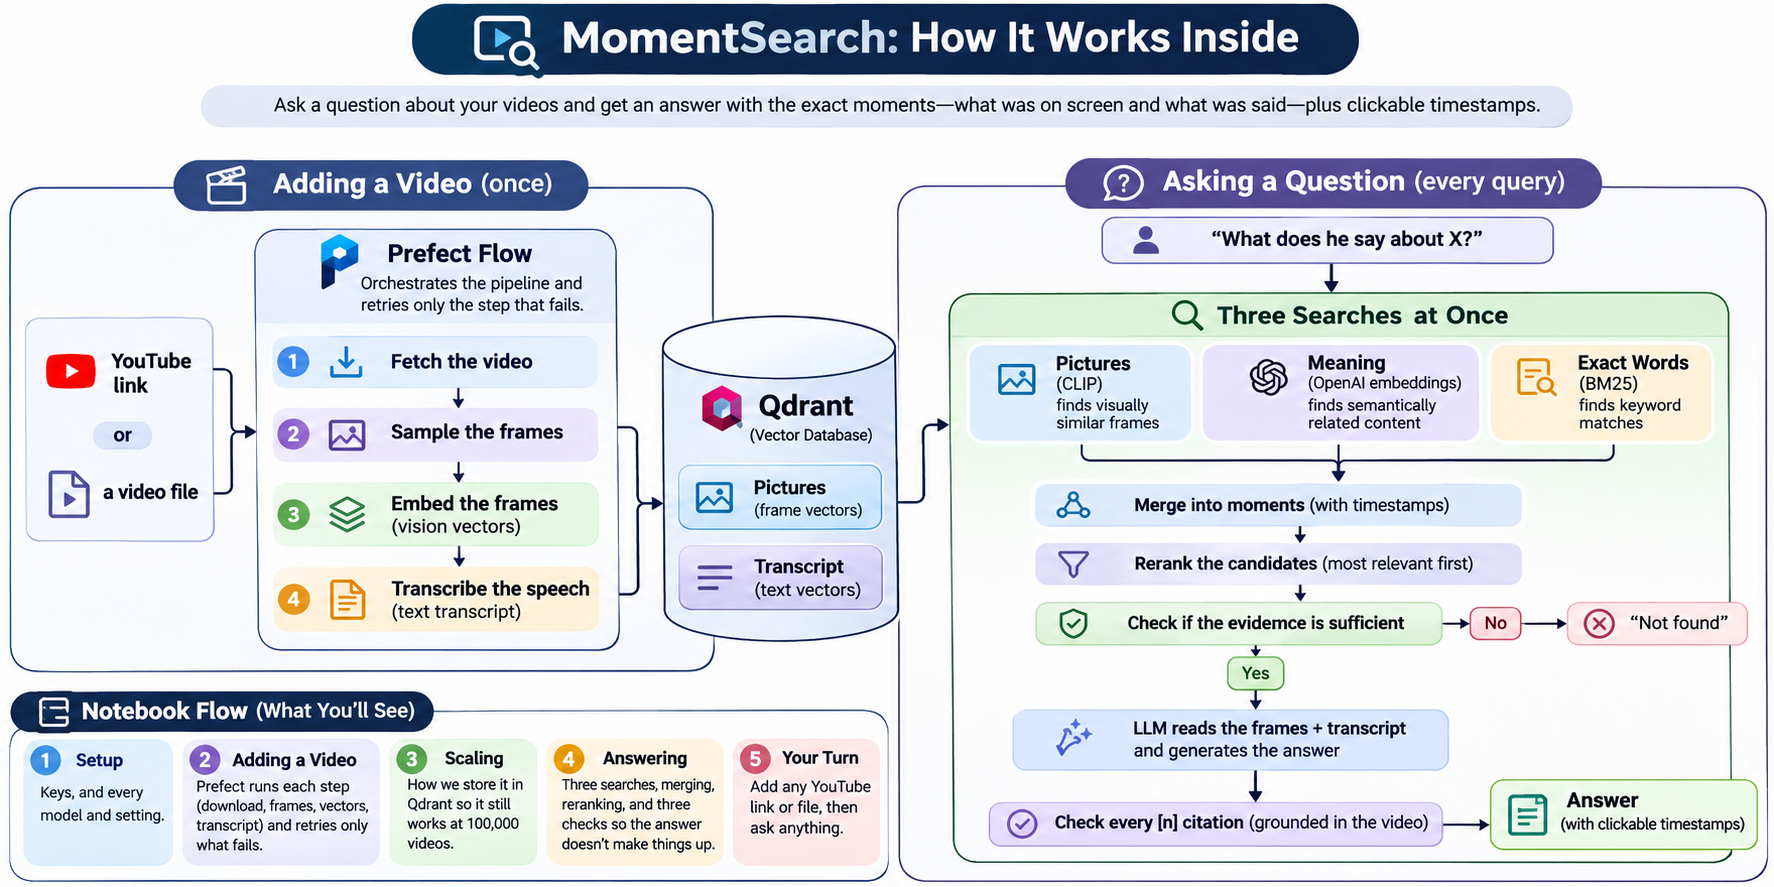

# MomentSearch: how it works inside

**MomentSearch** lets you ask a question about your videos and get an answer that points at the exact moments: what was **on screen** and what was **said**, with timestamps you can click.

This notebook runs the whole system right here in Colab, one step at a time, on one YouTube video. Every step shows what it does and why we built it that way. Nothing is downloaded from our GitHub: all the code is in the cells below.

The full product (API, web app, worker) is here: **[github.com/traversaal-ai/momentsearch](https://github.com/traversaal-ai/momentsearch)**.

| Part | What you'll see |
|---|---|
| **1. Setup** | the keys, and every model and setting we use |
| **2. Adding a video** | each step one at a time: download, frames, vectors, transcript |
| **3. Scaling the storage** | how we store it in Qdrant so it still works at 100,000 videos |
| **4. Running it for real** | Prefect runs the whole flow, retries only the step that fails, and a fair queue shares the workers |
| **5. Answering** | three searches, merging, reranking, and three checks so the answer doesn't make things up |
| **6. Your turn** | add any YouTube link or file, then ask anything |

You know what RAG and a vector database are. This notebook shows how they fit together here.

```
            ADDING A VIDEO  (once)                              ASKING  (every question)

  YouTube link ──┐                                          "What does he say about X?"
  or a file   ───┤                                                       │
                 ▼                                                       ▼
   ┌────────────────────────────┐                        ┌──────── three searches at once ────────┐
   │ Prefect flow               │                        │  pictures      meaning       exact     │
   │  1 fetch       the video   │                        │  (CLIP)        (OpenAI)      words     │
   │  2 sample      the frames  │                        │                              (BM25)    │
   │  3 embed       the frames ─┼──►  ┌────────────┐ ◄───┴────────────────────────────────────────┘
   │  4 transcript  the speech ─┼──►  │   Qdrant   │                      │
   └────────────────────────────┘     │ pictures   │          merge into moments → rerank
                                      │ transcript │                      │
                                      └────────────┘          sure enough? ── no ──► "not found"
                                                                          │ yes
                                                              LLM reads frames + transcript
                                                                          │
                                                              check every [n] citation ──► answer
```

# Part 1. Setup

## 1.1 Keys

Add these in **Colab secrets**: click the key icon in the left sidebar, add the name and value, and switch on **Notebook access**. **Add OpenAI, Prefect and SocialKit.** Qdrant and Gemini are optional.

> The free defaults for Prefect (a temporary server inside Colab) and YouTube (direct download with yt-dlp) **can fail in Colab**: the temporary Prefect server may not start properly, and YouTube often blocks Colab's servers. Add the Prefect and SocialKit keys to avoid this.

| Secret name | Needed? | What it does | If you leave it empty |
|---|---|---|---|
| `OPENAI_API_KEY` | **yes** | transcript vectors, speech-to-text for your own files, writing the answer | nothing works |
| `QDRANT_URL` + `QDRANT_API_KEY` | no | stores vectors in your Qdrant Cloud | a temporary Qdrant inside this Colab (gone when the session ends) |
| `PREFECT_API_URL` + `PREFECT_API_KEY` | **yes** | shows every run in your Prefect Cloud dashboard | a temporary Prefect server inside this Colab (**may fail**) |
| `GEMINI_API_KEY` | no | puts speaker names on the transcript ("who said what") | transcript has no names |
| `SOCIALKIT_API_KEY` | **yes** | downloads YouTube video and captions from SocialKit's servers | yt-dlp downloads them directly: free, but YouTube often blocks Colab (**may fail**) |

`PREFECT_API_URL` looks like `https://api.prefect.cloud/api/accounts/<account-id>/workspaces/<workspace-id>`.

> **Careful with production keys.** This notebook uses the product's collection names and flow name. If you give it the production Qdrant or Prefect, its test videos and runs land next to the real ones (in Qdrant they're stored under user `notebook`, so they stay separate and can be deleted). Use your own Qdrant cluster and Prefect workspace if you can.

In [1]:
# Install what Colab doesn't already have (about a minute).
# torch, ffmpeg, numpy, pandas and Pillow already come with Colab.
# If Colab asks you to restart the session afterwards, restart and run from the top.
import subprocess, sys
PACKAGES = ["prefect>=3", "qdrant-client>=1.12", "fastembed", "openai", "google-genai",
            "yt-dlp[default]", "sentence-transformers"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PACKAGES], check=True)
print("installed:", ", ".join(PACKAGES))

installed: prefect>=3, qdrant-client>=1.12, fastembed, openai, google-genai, yt-dlp[default], sentence-transformers


In [14]:
import os, tempfile
from pathlib import Path

def secret(name):
    """A Colab secret (key icon on the left), else an environment variable, else ""."""
    value = ""
    try:
        from google.colab import userdata
        value = userdata.get(name) or ""
    except Exception:      # not in Colab, secret not added, or notebook access switched off
        pass
    return (value or os.environ.get(name, "")).strip()

OPENAI_API_KEY    = secret("OPENAI_API_KEY")
QDRANT_URL        = secret("QDRANT_URL")
QDRANT_API_KEY    = secret("QDRANT_API_KEY")
PREFECT_API_URL   = secret("PREFECT_API_URL")
PREFECT_API_KEY   = secret("PREFECT_API_KEY")
GEMINI_API_KEY    = secret("GEMINI_API_KEY")
SOCIALKIT_API_KEY = secret("SOCIALKIT_API_KEY")
assert OPENAI_API_KEY, "Add OPENAI_API_KEY in Colab secrets (key icon, left sidebar) and switch on Notebook access."

IN_COLAB = Path("/content").exists()
WORK = Path("/content/momentsearch_data") if IN_COLAB else Path(tempfile.gettempdir()) / "momentsearch_data"
WORK.mkdir(parents=True, exist_ok=True)

# Keep model-download progress bars and cache warnings out of the outputs.
os.environ.update({"HF_HUB_DISABLE_PROGRESS_BARS": "1", "HF_HUB_DISABLE_SYMLINKS_WARNING": "1",
                   "TRANSFORMERS_VERBOSITY": "error", "TOKENIZERS_PARALLELISM": "false"})

# Prefect reads its settings the first time it is imported, so this must come first.
os.environ["PREFECT_LOGGING_TO_API_WHEN_MISSING_FLOW"] = "ignore"
if PREFECT_API_URL:
    os.environ["PREFECT_API_URL"] = PREFECT_API_URL
    os.environ["PREFECT_API_KEY"] = PREFECT_API_KEY
else:
    os.environ.pop("PREFECT_API_URL", None)   # no URL → Prefect starts a temporary server here
    os.environ.pop("PREFECT_API_KEY", None)
    os.environ["PREFECT_HOME"] = str(WORK / "prefect")
    (WORK / "prefect").mkdir(parents=True, exist_ok=True)

print(f"""Where everything runs
  vectors     : {"your Qdrant Cloud, " + QDRANT_URL if QDRANT_URL else "temporary Qdrant in this Colab, " + str(WORK / "qdrant")}
  pipeline    : {"your Prefect Cloud" if PREFECT_API_URL else "temporary Prefect server in this Colab"}
  YouTube     : {"SocialKit first, yt-dlp if that fails" if SOCIALKIT_API_KEY else "yt-dlp (free)"}
  speakers    : {"Gemini" if GEMINI_API_KEY else "off (no GEMINI_API_KEY)"}
  files       : {WORK / "objects"}   (plays the cloud bucket)
  video table : a Python dict            (plays Postgres)""")

Where everything runs
  vectors     : temporary Qdrant in this Colab, /content/momentsearch_data/qdrant
  pipeline    : your Prefect Cloud
  YouTube     : SocialKit first, yt-dlp if that fails
  speakers    : Gemini
  files       : /content/momentsearch_data/objects   (plays the cloud bucket)
  video table : a Python dict            (plays Postgres)


## 1.2 Models and settings

These are the product's defaults. Change any of them here and re-run from this cell.

* **Two collections** in Qdrant: one for pictures (one point per kept frame) and one for the transcript (one point per ~20-second chunk).
* **Pictures** are turned into vectors by **CLIP**, which runs here for free. CLIP puts images and text in the same space, so a typed question can find a frame.
* **Speech** is turned into vectors twice: **OpenAI** for meaning and **BM25** for exact words like names and numbers.

In [15]:
USER_ID = "notebook"     # every point in Qdrant is tagged with its owner

# ── models ───────────────────────────────────────────────────────────────────
CLIP_MODEL       = "clip-ViT-L-14"                   # frames + questions, same space. Free, runs here. 768 numbers
TEXT_EMBED_MODEL = "text-embedding-3-small"          # meaning of the transcript. OpenAI. 1536 numbers
SPARSE_MODEL     = "Qdrant/bm25"                     # exact words. Free, runs here
RERANK_MODEL     = "Xenova/ms-marco-MiniLM-L-6-v2"   # re-reads question + transcript together. Free, runs here
LLM_MODEL        = "gpt-4.1-mini"                        # writes the answer; it can see the frames
ASR_MODEL        = "whisper-1"                       # speech → text for your own files (YouTube has captions)
DIARIZE_MODEL    = "gemini-2.5-flash"                # who is speaking (only with GEMINI_API_KEY)

# ── Qdrant ───────────────────────────────────────────────────────────────────
IMAGE_COLLECTION    = "moments_l14"             # one point per kept frame
TEXT_COLLECTION     = "moments_text_openai"     # one point per transcript chunk: dense + BM25 vectors
SPARSE_VECTOR       = "bm25"                    # name of the BM25 vector inside TEXT_COLLECTION
QDRANT_ON_DISK      = True                      # full vectors live on disk
QDRANT_QUANTIZATION = True                      # a small int8 copy lives in RAM and does the searching
QDRANT_HNSW_ON_DISK = True                      # the search graph lives on disk too

# ── adding a video ───────────────────────────────────────────────────────────
FRAME_INTERVAL_SEC = 2.0     # one frame every 2 seconds
MAX_FRAMES         = 400     # long videos get wider spacing instead of more frames
THUMB_WIDTH        = 480     # frames are shrunk to 480 px wide in the same ffmpeg pass
THUMB_QUALITY      = 3       # JPEG quality (2 best .. 31 worst)
DEDUP_MAX_DISTANCE = 4       # frames this similar to the last kept one are dropped
CLIP_BATCH         = 128     # frames per embedding call
TRANSCRIPT_CHUNK_SECONDS = 20.0
TRANSCRIPT_LANGS   = ["en", "en-US", "en-GB"]

# ── answering ────────────────────────────────────────────────────────────────
BRANCH_TOP_K       = 20      # candidates from each search
TOP_K              = 6       # moments the LLM reads
RRF_K              = 60      # rank fusion constant: score = 1 / (60 + rank)
FUSION_WINDOW_S    = 15.0    # hits within 15 s of each other are one moment
CROSS_MODAL_BOOST  = 1.5     # a moment found by BOTH picture and speech counts 1.5x
RERANK_TOP_K       = 30
RERANK_WEIGHT      = 0.7     # 70% reranker, 30% fused rank
CONFIDENCE_THRESHOLD      = 0.2    # best picture match must reach this ...
TEXT_CONFIDENCE_THRESHOLD = 0.35   # ... or best transcript match this, or we don't answer
VISUAL_STRONG      = 0.45
TEXT_STRONG        = 0.65
CONTEXT_PAD_S      = 10.0    # the LLM also reads what was said 10 s around each moment
LLM_IMAGE_MAX_PX   = 512     # frames are shrunk again before the LLM sees them
LLM_MAX_TOKENS     = 1024
MULTI_QUERY_MAX_PARTS, MULTI_QUERY_TOTAL_K = 3, 12

# ── scaling the processing (explained in 4.2) ───────────────────────────────
DISPATCH_MAX_INFLIGHT = 2    # videos processed at once per worker

## 1.3 Connect

Qdrant: your cloud if you gave a URL, otherwise a local Qdrant saved to a folder in this Colab. OpenAI: three small functions that every later cell uses.

In [ ]:
import numpy as np
from qdrant_client import QdrantClient, models as qm
from openai import OpenAI

if QDRANT_URL:
    qdrant = QdrantClient(url=QDRANT_URL, api_key=QDRANT_API_KEY or None, timeout=60)
else:
    qdrant = QdrantClient(path=str(WORK / "qdrant"))     # local, saved to disk in this Colab
openai_client = OpenAI(api_key=OPENAI_API_KEY)

def normalize(vecs):
    vecs = np.asarray(vecs, dtype=np.float32)
    return vecs / np.maximum(np.linalg.norm(vecs, axis=-1, keepdims=True), 1e-12)

def embed_texts(texts):
    """Transcript chunks or a question → OpenAI vectors, unit length."""
    out = []
    for i in range(0, len(texts), 64):
        resp = openai_client.embeddings.create(model=TEXT_EMBED_MODEL, input=texts[i:i + 64])
        out += [d.embedding for d in sorted(resp.data, key=lambda d: d.index)]
    return normalize(out)

def chat(messages, max_tokens=LLM_MAX_TOKENS):
    """One chat call. Newer models renamed max_tokens or refuse a custom temperature: adapt and retry."""
    kwargs = {"model": LLM_MODEL, "messages": messages, "temperature": 0.2, "max_tokens": max_tokens}
    for _ in range(3):
        try:
            resp = openai_client.chat.completions.create(**kwargs)
            return (resp.choices[0].message.content or "").strip()
        except Exception as exc:
            msg = str(exc).lower()
            if "max_completion_tokens" in msg and "max_tokens" in kwargs:
                kwargs["max_completion_tokens"] = kwargs.pop("max_tokens")
            elif "temperature" in msg and "temperature" in kwargs:
                kwargs.pop("temperature")
            else:
                raise
    raise RuntimeError("chat call kept failing")

def whisper_segments(audio_path, offset=0.0):
    """One audio file → timed text [{text, t_start, t_end}], times shifted by `offset` seconds."""
    with open(audio_path, "rb") as fh:
        resp = openai_client.audio.transcriptions.create(
            file=fh, model=ASR_MODEL, response_format="verbose_json",
            timestamp_granularities=["segment"])
    cues = []
    for s in resp.segments or []:
        text = (s.text or "").strip()
        if text:
            cues.append({"text": text, "t_start": s.start + offset, "t_end": s.end + offset})
    return cues

In [18]:
# Check the key now, not ten minutes into processing.
TEXT_DIM = embed_texts(["hello"]).shape[1]
chat([{"role": "user", "content": "Reply with OK."}], max_tokens=16)
print(f"OpenAI key works: {TEXT_EMBED_MODEL} gives {TEXT_DIM} numbers per text, and {LLM_MODEL} answers.")

OpenAI key works: text-embedding-3-small gives 1536 numbers per text, and gpt-4.1-mini answers.


## 1.4 Small helpers

* **`VIDEOS`** is the video table. In the product it's a Postgres table: the API writes one `pending` row and returns at once, and the worker updates the row as it goes.
* **`put_bytes` / `get_bytes`** play the cloud bucket (GCS, S3 or R2 in the product). The key layout is the same: everything for one video lives under `<user>/<video>/`.
* The rest are for showing results.

In [19]:
import io, re, json, time, uuid, base64, shutil, hashlib, subprocess, warnings
from dataclasses import dataclass
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
from PIL import Image
from IPython.display import display, HTML, Markdown

warnings.filterwarnings("ignore", message=".*Payload indexes have no effect.*")
warnings.filterwarnings("ignore", message=".*Local mode performs exact.*")
warnings.filterwarnings("ignore", message=".*Cannot enable progress bars.*")
pd.set_option("display.max_colwidth", 110)

# ── the video table (Postgres in the product) ────────────────────────────────
VIDEOS = {}

def set_status(vid, status, **fields):
    row = VIDEOS[vid]
    if row["status"] != status or not row["timeline"]:
        row["timeline"].append((time.time(), status))
    row["status"] = status
    row.update(fields)

# ── the bucket (GCS / S3 / R2 in the product) ────────────────────────────────
STORE = WORK / "objects"
def video_prefix(vid):       return f"{USER_ID}/{vid}/"
def frame_key(vid, i):       return f"{video_prefix(vid)}frames/{i:06d}.jpg"
def transcript_key(vid):     return f"{video_prefix(vid)}transcript.json"
def put_bytes(key, data):
    p = STORE / key
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_bytes(data)
def get_bytes(key):          return (STORE / key).read_bytes()
def delete_prefix(prefix):   shutil.rmtree(STORE / prefix, ignore_errors=True)

# ── showing things ───────────────────────────────────────────────────────────
def mmss(sec):
    s = int(sec)
    return f"{s // 60:02d}:{s % 60:02d}"

def short(text, n=100):
    text = " ".join(str(text or "").split())
    return text if len(text) <= n else text[:n - 1] + "…"

def img_tag(jpeg, width=150):
    return f'<img src="data:image/jpeg;base64,{base64.b64encode(jpeg).decode()}" width="{width}">'

def strip(items, width=150):
    """items: [(jpeg_bytes, caption)] → a row of pictures."""
    cells = "".join(f'<div style="margin:3px;text-align:center;font:12px monospace">{img_tag(j, width)}<br>{c}</div>'
                    for j, c in items)
    display(HTML(f'<div style="display:flex;flex-wrap:wrap">{cells}</div>'))

def table(rows, columns=None):
    display(pd.DataFrame(rows, columns=columns).style.hide(axis="index").format(precision=3))

def timeline(vid):
    tl = VIDEOS[vid]["timeline"]
    print("  →  ".join(f"{s} (+{t - tl[0][0]:.0f}s)" for t, s in tl))

# Part 2. Adding a video

```
  status:   pending ──► fetching ──► sampling ──► embedding ──► indexed
                                                      (or failed / skipped)

  ┌──────────────┐    ┌──────────────┐    ┌──────────────┐    ┌──────────────┐
  │ 1 fetch      │ ─► │ 2 sample     │ ─► │ 3 embed-index│ ─► │ 4 transcript │
  │ retries: 2   │    │ retries: 0   │    │ retries: 2   │    │ retries: 1   │
  └──────────────┘    └──────────────┘    └──────────────┘    └──────────────┘
   download the        1 frame / 2 s,      CLIP vectors         captions or speech-to-text
   video (≤480p)       drop repeats,       → Qdrant             → speaker names (Gemini)
                       save thumbnails     (pictures)           → 20 s chunks → OpenAI + BM25
                                                                → Qdrant (transcript)
```

**Why Prefect?** Each step is a Prefect **task** with its own retry rule, and the four together are a **flow**.
* If step 3 fails, Prefect retries step 3 only. It does not download the video again.
* Downloads fail for passing reasons (network, YouTube rate limits), so fetch waits 30 s, then 2 min, before giving up.
* Every run is recorded: start, end, retries and logs. That's here, or in your Prefect Cloud if you added the key.

Below we call the four tasks one at a time so you can look inside each. Part 3 explains how Qdrant stores what they write, and in Part 4 the same four run as one real Prefect flow.

In [20]:
from prefect import flow, task

NB_TAG = "momentsearch-notebook"   # tags this notebook's task runs, so we list only ours

YT_ID = re.compile(r"(?:v=|youtu\.be/|shorts/|embed/|live/)([A-Za-z0-9_-]{11})")

def youtube_id(source):
    m = YT_ID.search(source) if "youtu" in source else None
    return m.group(1) if m else None

def video_id(source):
    """yt_<id> for a YouTube link. Files get a new random id each time they are added."""
    yt = youtube_id(str(source))
    return f"yt_{yt}" if yt else None

def resolve_path(source):
    """A file path as typed, or relative to /content (where Colab's Files panel uploads)."""
    p = Path(str(source).strip())
    for cand in (p, Path("/content") / p):
        if cand.is_file():
            return cand
    raise FileNotFoundError(f"{source} not found. Upload it with the Files panel on the left, "
                            f"then use its path, for example /content/my_video.mp4")

def add_video(source, diarize=True):
    """Register a video: one 'pending' row. That's all the product's API does before it answers."""
    source = str(source).strip()
    vid = video_id(source)
    if vid:
        row = {"source": "youtube", "url": f"https://www.youtube.com/watch?v={youtube_id(source)}", "path": None}
    else:
        path = resolve_path(source)
        vid = "up_" + uuid.uuid4().hex[:10]
        row = {"source": "upload", "url": None, "path": str(path)}
    VIDEOS[vid] = {"id": vid, "user_id": USER_ID, "status": "pending", "timeline": [], "attempts": 0,
                   "title": None, "source_hash": None, "frame_count": None, "chunks": 0,
                   "error": None, "transcript_note": None, "diarize": diarize, **row}
    set_status(vid, "pending")
    return vid

Our demo video: *Large Language Models explained briefly* (3Blue1Brown, 8 minutes). It has slides, diagrams and clear speech, so it's a good test for both pictures and transcript.

In [21]:
VIDEO = "https://www.youtube.com/watch?v=LPZh9BOjkQs"

VID = add_video(VIDEO)
print("video id:", VID)
print({k: VIDEOS[VID][k] for k in ("source", "url", "status", "diarize")})

video id: yt_LPZh9BOjkQs
{'source': 'youtube', 'url': 'https://www.youtube.com/watch?v=LPZh9BOjkQs', 'status': 'pending', 'diarize': True}


## 2.1 Fetch: get the video file

* **YouTube:** we download a **≤480p, video-only** stream. CLIP shrinks every picture to 224×224 anyway, so 4K would only waste bandwidth. Audio isn't needed because YouTube has captions.
  * With a SocialKit key, SocialKit downloads it from its own servers. That avoids YouTube blocking cloud IPs like Colab's.
  * Without the key, or if SocialKit fails, yt-dlp downloads it directly. If that fails, yt-dlp tries again with other YouTube player clients.
* **Your own file:** copied into the worker's scratch folder. In the product, the browser uploads straight to the bucket and the worker downloads it from there.
* **Duplicates:** we fingerprint the content (the YouTube id, or a SHA-256 of the file). If you already have it indexed, the video is marked `skipped` instead of being processed twice.

The scratch copy is deleted when the run ends. Only thumbnails, the transcript and the vectors are kept.

In [22]:
import urllib.request, urllib.parse

SCRATCH = WORK / "scratch"     # the worker's temp space
SOCIALKIT_BASE_URL = "https://api.socialkit.dev"
_UA = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0 Safari/537.36"

def ffprobe(path):
    """duration (s), width, height and frame rate of a video file."""
    out = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0",
                          "-show_entries", "stream=width,height,avg_frame_rate:format=duration",
                          "-of", "json", str(path)], capture_output=True, text=True)
    info = json.loads(out.stdout or "{}")
    st = (info.get("streams") or [{}])[0]
    num, den = (st.get("avg_frame_rate") or "0/1").split("/")
    return {"duration": float((info.get("format") or {}).get("duration") or 0),
            "width": st.get("width"), "height": st.get("height"),
            "fps": float(num) / float(den) if float(den) else 0.0}

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        while chunk := fh.read(1 << 20):
            h.update(chunk)
    return h.hexdigest()

# ── SocialKit: video + captions from its servers ─────────────────────────────
def socialkit(path, params=None, body=None):
    """GET (params) or POST (body) to SocialKit → JSON, or None on any error."""
    url = f"{SOCIALKIT_BASE_URL}{path}"
    if body is None:
        url += "?" + urllib.parse.urlencode({**(params or {}), "access_key": SOCIALKIT_API_KEY})
        req = urllib.request.Request(url, headers={"User-Agent": _UA})
    else:
        req = urllib.request.Request(url, data=json.dumps({**body, "access_key": SOCIALKIT_API_KEY}).encode(),
                                     headers={"Content-Type": "application/json", "User-Agent": _UA})
    try:
        with urllib.request.urlopen(req, timeout=60) as resp:
            return json.loads(resp.read().decode("utf-8", errors="replace"))
    except Exception as exc:
        print(f"[socialkit] {type(exc).__name__}: {str(exc)[:150]}")
        return None

def socialkit_video(url, vid):
    """Submit a download job, poll until ready, download the file. None if anything fails."""
    job = ((socialkit("/v2/youtube/download", body={"url": url, "quality": "480p", "format": "mp4"}) or {})
           .get("data") or {}).get("jobId")
    if not job:
        return None
    info, deadline = {}, time.monotonic() + 420
    while time.monotonic() < deadline:
        time.sleep(4)
        info = (socialkit(f"/v2/downloads/{job}") or {}).get("data") or {}
        if info.get("status") in ("ready", "failed"):
            break
    if info.get("status") != "ready" or not info.get("downloadUrl"):
        return None
    dest = SCRATCH / f"{vid}.mp4"
    try:
        req = urllib.request.Request(info["downloadUrl"], headers={"User-Agent": _UA})
        with urllib.request.urlopen(req, timeout=60) as resp, open(dest, "wb") as fh:
            shutil.copyfileobj(resp, fh, 1 << 20)
    except Exception as exc:
        print(f"[socialkit] file download failed: {exc}")
        dest.unlink(missing_ok=True)
        return None
    return dest, info.get("title") or vid

# ── yt-dlp: the free way ─────────────────────────────────────────────────────
def yt_opts(vid, clients=None):
    opts = {
        "format": ("bestvideo[height<=480][ext=mp4]/bestvideo[height<=480]/best[height<=480][ext=mp4]/"
                   "best[height<=480]/bestvideo[ext=mp4]/bestvideo/best"),
        "outtmpl": str(SCRATCH / f"{vid}.%(ext)s"),
        "quiet": True, "no_warnings": True, "noprogress": True, "noplaylist": True,
        "remote_components": ["ejs:github"],   # YouTube's JS challenge solver
    }
    runtimes = {r: {} for r in ("deno", "node") if shutil.which(r)}
    if runtimes:
        opts["js_runtimes"] = runtimes
    if clients:
        opts["extractor_args"] = {"youtube": {"player_client": clients}}
    return opts

def download_youtube(url, vid):
    if SOCIALKIT_API_KEY:
        hit = socialkit_video(url, vid)
        if hit:
            return hit
        print("SocialKit couldn't download it, trying yt-dlp")
    import yt_dlp
    last = None
    for clients in (None, ["tv", "android", "ios"]):
        try:
            with yt_dlp.YoutubeDL(yt_opts(vid, clients)) as ydl:
                info = ydl.extract_info(url, download=True)
                return Path(ydl.prepare_filename(info)), info.get("title") or vid
        except Exception as exc:
            last = exc
            print(f"yt-dlp: {str(exc)[:120]}")
    raise RuntimeError(f"Couldn't download {url} ({last}). YouTube often blocks cloud servers like "
                       "Colab's: add SOCIALKIT_API_KEY in secrets, or upload the file and use its path.")

# ── the task ─────────────────────────────────────────────────────────────────
@task(name="fetch", retries=2, retry_delay_seconds=[30, 120], tags=[NB_TAG])
def t_fetch(vid):
    set_status(vid, "fetching")
    row = VIDEOS[vid]
    SCRATCH.mkdir(parents=True, exist_ok=True)
    if row["source"] == "youtube":
        path, title = download_youtube(row["url"], vid)
        source_hash = vid                        # the YouTube id IS the content's identity
    else:
        src = Path(row["path"])
        path = SCRATCH / f"{vid}{src.suffix or '.mp4'}"
        shutil.copyfile(src, path)
        title, source_hash = src.stem, sha256_file(path)
    set_status(vid, "fetching", title=title, source_hash=source_hash)

    dup = next((r for r in VIDEOS.values() if r["id"] != vid and r["source_hash"] == source_hash
                and r["status"] == "indexed"), None)
    if dup:
        path.unlink(missing_ok=True)
        set_status(vid, "skipped", error=f"duplicate of {dup['id']}")
        print(f"{vid}: same content as {dup['id']}, skipped")
        return ""
    return str(path)

In [23]:
PATH = t_fetch(VID)
INFO = ffprobe(PATH)
print(f"title     : {VIDEOS[VID]['title']}")
print(f"file      : {Path(PATH).name}, {Path(PATH).stat().st_size / 1e6:.1f} MB")
print(f"video     : {INFO['width']}x{INFO['height']}, {INFO['fps']:.0f} fps, {mmss(INFO['duration'])} long")

INFO:prefect.task_runs:Finished in state Completed()


title     : Large Language Models explained briefly
file      : yt_LPZh9BOjkQs.mp4, 23.6 MB
video     : 854x480, 30 fps, 07:57 long


## 2.2 Sample: pick the frames worth keeping

An 8-minute video at 30 fps has over 14,000 frames. Almost all of them repeat their neighbours. **Sampling is the biggest scaling lever we have**: it's what stops thousands of videos from turning into billions of near-identical vectors.

* **One ffmpeg pass** does everything: decode, take one frame every 2 s, shrink to 480 px wide, encode as JPEG.
* The JPEGs come out through a pipe into memory. No frame is written to disk and read back.
* Long videos are capped at 400 frames: the spacing widens instead of the count growing.

In [24]:
@dataclass
class Frame:
    ms: int        # where in the video
    jpeg: bytes    # the shrunk JPEG

def split_mjpeg(stream):
    """ffmpeg writes JPEGs back to back; each starts with FFD8 and ends with FFD9."""
    frames, pos = [], 0
    while (start := stream.find(b"\xff\xd8", pos)) >= 0:
        end = stream.find(b"\xff\xd9", start + 2)
        if end < 0:
            break
        frames.append(stream[start:end + 2])
        pos = end + 2
    return frames

def run_ffmpeg(path, vf):
    err = ""
    for sync in (["-vsync", "vfr"], ["-fps_mode", "vfr"]):     # older ffmpeg (Colab) / newer ffmpeg
        proc = subprocess.run(["ffmpeg", "-loglevel", "error", "-i", str(path), "-vf", vf, *sync,
                               "-f", "image2pipe", "-vcodec", "mjpeg", "-q:v", str(THUMB_QUALITY), "-"],
                              capture_output=True)
        if proc.stdout:
            return proc.stdout
        err = proc.stderr.decode(errors="replace")
        if "nrecognized option" not in err and "not found" not in err:
            break
    last = [l for l in err.strip().splitlines() if l.strip()][-1:] or ["no output"]
    raise RuntimeError(f"ffmpeg couldn't read this file: {last[0][:200]}")

def sample_frames(path):
    interval = FRAME_INTERVAL_SEC
    duration = ffprobe(path)["duration"]
    if MAX_FRAMES and duration / interval > MAX_FRAMES:
        interval = duration / MAX_FRAMES
    jpegs = split_mjpeg(run_ffmpeg(path, f"fps=1/{interval:.6f},scale='min({THUMB_WIDTH},iw)':-2"))
    return [Frame(ms=int(round(i * interval * 1000)), jpeg=j) for i, j in enumerate(jpegs)]

14,325 frames in the video → 239 sampled in 18.3 s

How many pixels each stage keeps:


stage,size,why
downloaded video,854x480,"≤480p, no audio: we never need 4K"
stored thumbnail,"480x270 JPEG, ~17 KB","small enough to keep thousands, sharp enough to read a slide"
what CLIP sees,224x224,the model shrinks every picture to this anyway
what the LLM sees,≤512 px,"fewer image tokens: faster, cheaper answers"



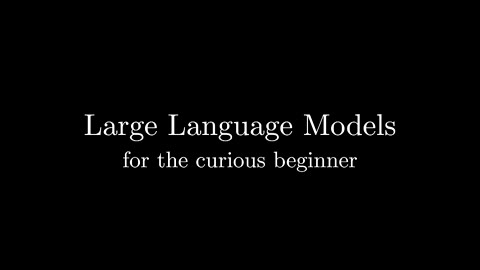
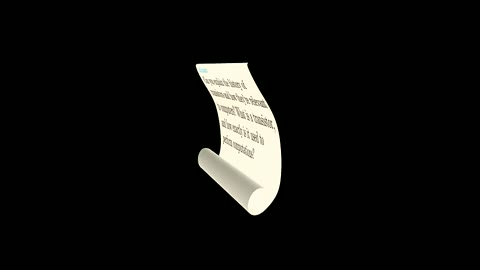
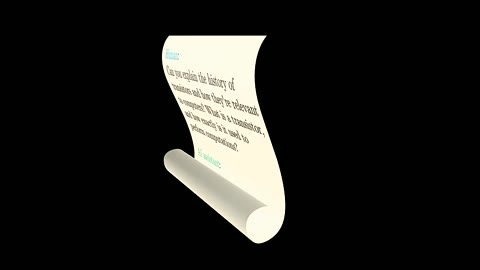
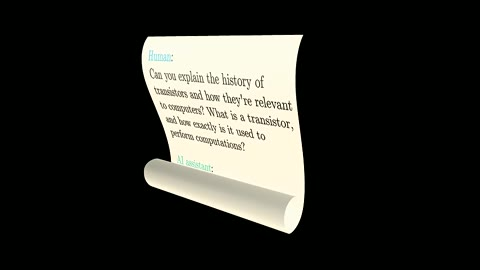
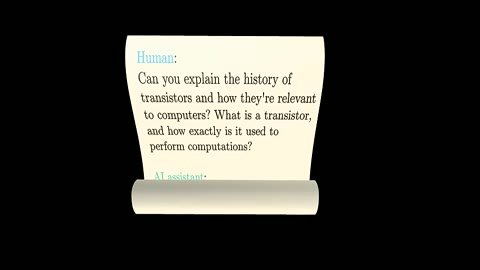
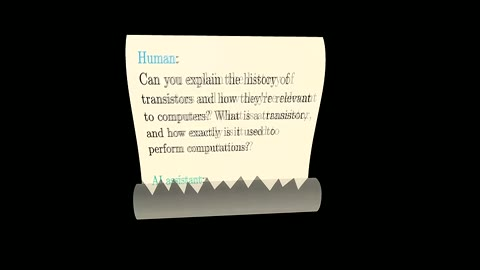
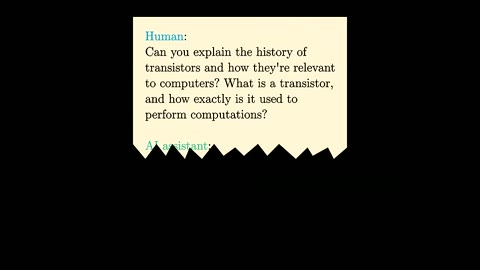
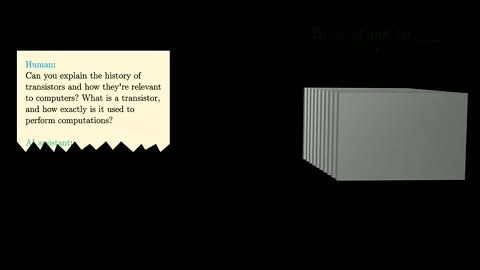
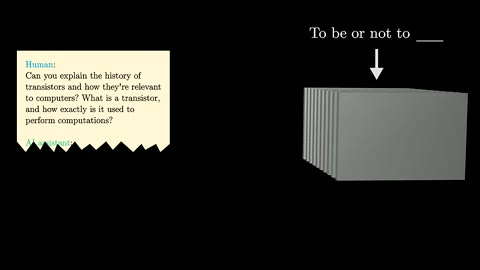
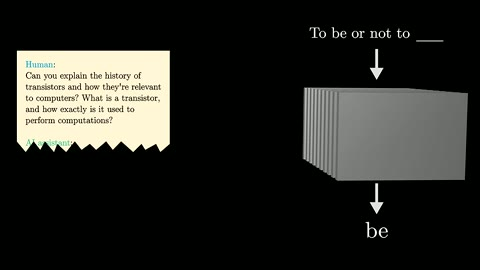

In [25]:
t = time.time()
SAMPLED = sample_frames(PATH)
w, h = Image.open(io.BytesIO(SAMPLED[0].jpeg)).size
avg_kb = sum(len(f.jpeg) for f in SAMPLED) / len(SAMPLED) / 1024
print(f"{int(INFO['duration'] * INFO['fps']):,} frames in the video → {len(SAMPLED)} sampled in {time.time() - t:.1f} s\n")

print("How many pixels each stage keeps:")
table([
    ["downloaded video",  f"{INFO['width']}x{INFO['height']}", "≤480p, no audio: we never need 4K"],
    ["stored thumbnail",  f"{w}x{h} JPEG, ~{avg_kb:.0f} KB", "small enough to keep thousands, sharp enough to read a slide"],
    ["what CLIP sees",    "224x224", "the model shrinks every picture to this anyway"],
    ["what the LLM sees", f"≤{LLM_IMAGE_MAX_PX} px", "fewer image tokens: faster, cheaper answers"],
], ["stage", "size", "why"])
strip([(f.jpeg, mmss(f.ms / 1000)) for f in SAMPLED[:10]], width=140)

## 2.3 Drop repeats

Slides, talking heads and pauses produce many frames that look the same. Each one would cost a CLIP call, a thumbnail and a vector, and add nothing.

**How:** shrink each frame to 9×8 grey pixels and record whether each pixel is brighter than its right-hand neighbour. That gives a 64-bit fingerprint (a "dHash"). If a frame's fingerprint differs from the **last kept** frame by 4 bits or fewer, and its brightness is about the same, it's a repeat and we drop it. Any real change on screen gets through.

In [26]:
def dhash(jpeg):
    """(64-bit fingerprint, average brightness)"""
    img = Image.open(io.BytesIO(jpeg)).convert("L").resize((9, 8), Image.LANCZOS)
    px = np.asarray(img, dtype=np.int16)
    bits = (px[:, 1:] > px[:, :-1]).flatten()
    return int(np.packbits(bits).tobytes().hex(), 16), float(px.mean())

def same(a, b):
    return (a[0] ^ b[0]).bit_count() <= DEDUP_MAX_DISTANCE and abs(a[1] - b[1]) <= 10

def dedup(frames, dropped=None):
    """Keep a frame only if it differs from the last kept one. `dropped` collects (kept, dropped) pairs."""
    if len(frames) < 2:
        return frames
    kept, last = [frames[0]], dhash(frames[0].jpeg)
    for f in frames[1:]:
        h = dhash(f.jpeg)
        if same(h, last):
            if dropped is not None:
                dropped.append((kept[-1], f))
        else:
            kept.append(f)
            last = h
    return kept

239 sampled → 155 kept. 84 repeats dropped (35%).

A few dropped frames (right) next to the kept frame they repeat (left):



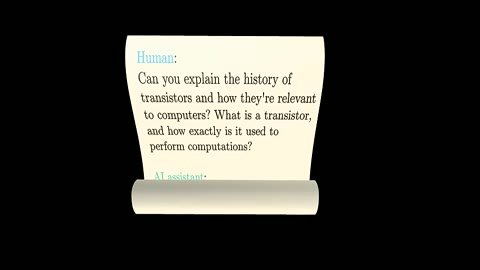
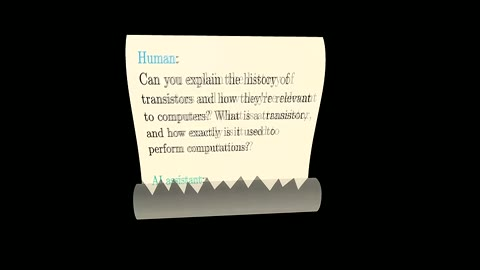


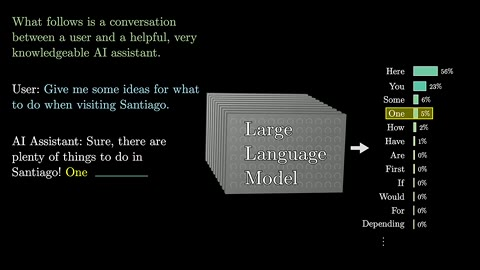
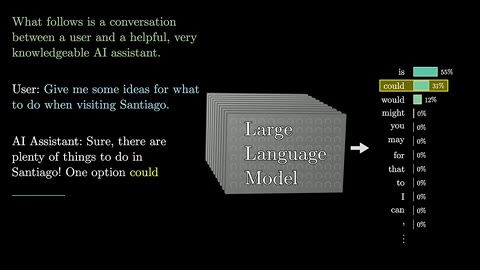


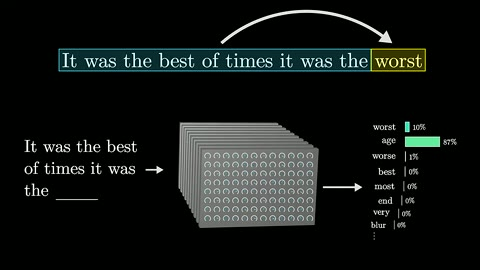
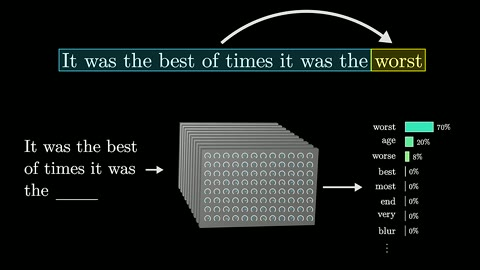


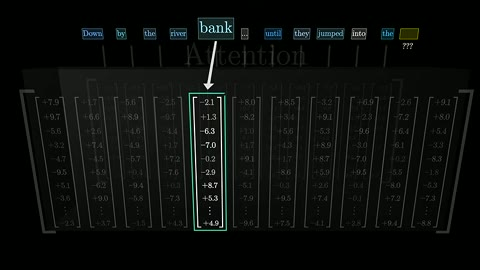
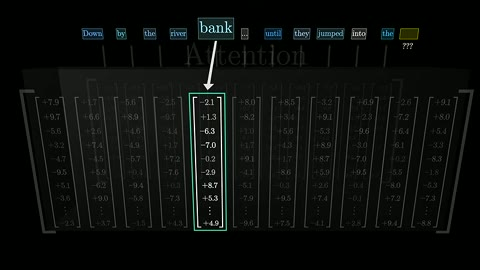

In [27]:
pairs = []
kept_preview = dedup(SAMPLED, dropped=pairs)
print(f"{len(SAMPLED)} sampled → {len(kept_preview)} kept. "
      f"{len(SAMPLED) - len(kept_preview)} repeats dropped ({1 - len(kept_preview) / len(SAMPLED):.0%}).\n")
print("A few dropped frames (right) next to the kept frame they repeat (left):")
step = max(1, len(pairs) // 4)
for kept_f, drop_f in pairs[::step][:4]:
    strip([(kept_f.jpeg, f"kept {mmss(kept_f.ms / 1000)}"), (drop_f.jpeg, f"dropped {mmss(drop_f.ms / 1000)}")], width=170)

## 2.4 The `sample` task: sample, drop repeats, save thumbnails

The task puts 2.2 and 2.3 together and saves each kept frame to the bucket (8 uploads at a time). The thumbnails are what the answer cards show and what the LLM looks at later.

It has **no retries**: if ffmpeg can't read the file, trying again won't help.

In [28]:
SAMPLE_COUNTS = {}    # vid → (sampled, kept), for the scaling numbers in Part 3

@task(name="sample", tags=[NB_TAG])
def t_sample(vid, path):
    set_status(vid, "sampling", progress=0.0)
    frames = sample_frames(Path(path))
    if not frames:
        raise RuntimeError("No frames could be extracted from the video.")
    kept = dedup(frames)
    print(f"{vid}: {len(frames)} sampled → {len(kept)} after dropping repeats")
    delete_prefix(f"{video_prefix(vid)}frames/")          # a re-run starts clean
    with ThreadPoolExecutor(max_workers=8) as ex:
        list(ex.map(lambda i_f: put_bytes(frame_key(vid, i_f[0]), i_f[1].jpeg), enumerate(kept)))
    SAMPLE_COUNTS[vid] = (len(frames), len(kept))
    set_status(vid, "sampling", progress=1.0)
    return kept

KEPT = t_sample(VID, PATH)
files = sorted((STORE / video_prefix(VID) / "frames").iterdir())
print(f"\nbucket: {len(files)} thumbnails, {sum(f.stat().st_size for f in files) / 1e6:.1f} MB in total")
for f in files[:3]:
    print("  ", f.relative_to(STORE).as_posix())

INFO:prefect.task_runs:Finished in state Completed()


yt_LPZh9BOjkQs: 239 sampled → 155 after dropping repeats

bucket: 155 thumbnails, 2.6 MB in total
   notebook/yt_LPZh9BOjkQs/frames/000000.jpg
   notebook/yt_LPZh9BOjkQs/frames/000001.jpg
   notebook/yt_LPZh9BOjkQs/frames/000002.jpg


## 2.5 Turn pictures into vectors (CLIP)

CLIP was trained on hundreds of millions of image + caption pairs, so it puts a picture and a sentence that describes it **close together in the same space**. That's what lets a typed question find a frame.

* It runs right here: free, no key. On a GPU runtime it takes seconds; on CPU, a few minutes per video.
* `clip-ViT-L-14` gives 768 numbers per frame. Vectors are made unit length, so cosine similarity is a dot product.

clip-ViT-L-14 on cuda: 768 numbers per frame




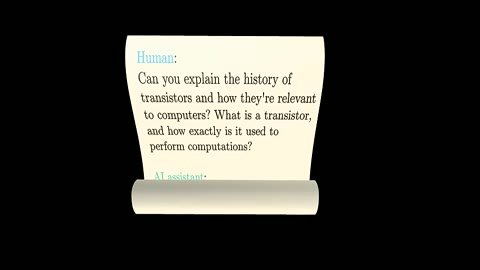

sentence,similarity to this frame
a scroll of paper with a question written on it,0.245
a diagram of a neural network,0.172
a bowl of soup on a table,0.136
a cat sleeping on a sofa,0.118


In [29]:
import torch
from sentence_transformers import SentenceTransformer

import threading

try:
    import logging, transformers
    transformers.utils.logging.disable_progress_bar()
    logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
except Exception:
    pass

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
clip = SentenceTransformer(CLIP_MODEL, device=DEVICE)
_clip_lock = threading.Lock()          # the model isn't thread-safe; searches run in threads

def embed_images(jpegs):
    images = [Image.open(io.BytesIO(j)).convert("RGB") for j in jpegs]
    with _clip_lock:
        return normalize(clip.encode(images, batch_size=32, convert_to_numpy=True, show_progress_bar=False))

def embed_clip_text(text):
    """A question → the same space as the frames."""
    with _clip_lock:
        return normalize(clip.encode([text], convert_to_numpy=True, show_progress_bar=False))[0]

IMAGE_DIM = len(embed_clip_text("hello"))
print(f"{CLIP_MODEL} on {DEVICE}: {IMAGE_DIM} numbers per frame\n")

# Same space: compare one frame (the one 8 s in) with a few sentences. The right one scores highest.
f0 = min(KEPT, key=lambda f: abs(f.ms - 8000))
v = embed_images([f0.jpeg])[0]
strip([(f0.jpeg, mmss(f0.ms / 1000))], width=260)
table([[s, float(v @ embed_clip_text(s))] for s in
       ["a scroll of paper with a question written on it", "a diagram of a neural network",
        "a bowl of soup on a table", "a cat sleeping on a sofa"]],
      ["sentence", "similarity to this frame"])

## 2.6 The `embed-index` task: frames into Qdrant

Each kept frame becomes one **point**: its CLIP vector plus a small payload (`user_id`, `video_id`, time in ms, frame number).

How the collection is created (Part 3 explains why):
* `on_disk`: full-size vectors live on disk, not in RAM.
* `int8` quantization with `always_ram`: a 4× smaller copy stays in RAM and does the searching.
* HNSW graph `on_disk`.
* A **tenant index** on `user_id` (one collection shared by every user) and an index on `video_id`.

Point ids are made from `video_id:frame_number`, so running the task again **overwrites** points instead of duplicating them. That's what makes Prefect's retries safe. The task also starts by deleting the video's old points.

Retries: 2, one minute apart (e.g. Qdrant Cloud briefly unreachable).

In [30]:
def create_collection(name, dim, sparse=False):
    qdrant.create_collection(
        collection_name=name,
        vectors_config=qm.VectorParams(size=dim, distance=qm.Distance.COSINE, on_disk=QDRANT_ON_DISK),
        hnsw_config=qm.HnswConfigDiff(on_disk=QDRANT_HNSW_ON_DISK),
        quantization_config=(qm.ScalarQuantization(scalar=qm.ScalarQuantizationConfig(
            type=qm.ScalarType.INT8, always_ram=True)) if QDRANT_QUANTIZATION else None),
        # BM25: Qdrant applies the IDF half at query time from live stats, so points never go stale
        sparse_vectors_config={SPARSE_VECTOR: qm.SparseVectorParams(modifier=qm.Modifier.IDF)} if sparse else None,
    )
    qdrant.create_payload_index(name, "user_id", field_schema=qm.KeywordIndexParams(
        type=qm.KeywordIndexType.KEYWORD, is_tenant=True))
    qdrant.create_payload_index(name, "video_id", field_schema=qm.PayloadSchemaType.KEYWORD)

def ensure_collection(name, dim, sparse=False):
    if not qdrant.collection_exists(name):
        create_collection(name, dim, sparse)
        return
    found = getattr(qdrant.get_collection(name).config.params.vectors, "size", None)
    if found and found != dim:      # a different model was used before: its vectors can't be compared
        raise RuntimeError(f"'{name}' holds {found}-number vectors but the model makes {dim}. "
                           "Use the old model, or pick a new collection name.")

def point_id(vid, idx):
    return str(uuid.uuid5(uuid.NAMESPACE_URL, f"{vid}:{idx}"))

def owner_filter(video_ids=None, user_id=None):
    """Every search and delete goes through this: only this user's points, optionally only some videos."""
    must = [qm.FieldCondition(key="user_id", match=qm.MatchValue(value=user_id or USER_ID))]
    if video_ids:
        must.append(qm.FieldCondition(key="video_id", match=qm.MatchAny(any=list(video_ids))))
    return qm.Filter(must=must)

def delete_video(vid):
    for coll in (IMAGE_COLLECTION, TEXT_COLLECTION):
        if qdrant.collection_exists(coll):
            qdrant.delete(coll, points_selector=qm.FilterSelector(filter=owner_filter([vid])), wait=True)

@task(name="embed-index", retries=2, retry_delay_seconds=60, tags=[NB_TAG])
def t_embed_index(vid, frames):
    set_status(vid, "embedding", progress=0.0)
    ensure_collection(IMAGE_COLLECTION, IMAGE_DIM)
    delete_video(vid)                                      # drop points from an earlier attempt
    for start in range(0, len(frames), CLIP_BATCH):
        batch = frames[start:start + CLIP_BATCH]
        vecs = embed_images([f.jpeg for f in batch])
        qdrant.upsert(IMAGE_COLLECTION, wait=True, points=[
            qm.PointStruct(id=point_id(vid, start + i), vector=v.tolist(), payload={
                "user_id": USER_ID, "video_id": vid, "ms": f.ms, "idx": start + i, "modality": "frame",
                "t_start": f.ms / 1000, "t_end": f.ms / 1000, "embed_version": f"{CLIP_MODEL}-v1"})
            for i, (f, v) in enumerate(zip(batch, vecs))])
        set_status(vid, "embedding", progress=(start + len(batch)) / len(frames))
    set_status(vid, "indexed", frame_count=len(frames), progress=1.0)
    return len(frames)

In [31]:
t = time.time()
n = t_embed_index(VID, KEPT)
count = qdrant.count(IMAGE_COLLECTION, count_filter=owner_filter([VID]), exact=True).count
print(f"\n{n} frames embedded and stored in {time.time() - t:.0f} s. Points in '{IMAGE_COLLECTION}' for this video: {count}")
print("One point's payload:", qdrant.scroll(IMAGE_COLLECTION, scroll_filter=owner_filter([VID]), limit=1)[0][0].payload)

INFO:prefect.task_runs:Finished in state Completed()



155 frames embedded and stored in 9 s. Points in 'moments_l14' for this video: 155
One point's payload: {'user_id': 'notebook', 'video_id': 'yt_LPZh9BOjkQs', 'ms': 182000, 'idx': 47, 'modality': 'frame', 't_start': 182.0, 't_end': 182.0, 'embed_version': 'clip-ViT-L-14-v1'}


**Try it: search the pictures with words.** The sentence goes through CLIP's text side and lands near the frames that look like it.

"a graph with arrows connecting nodes"



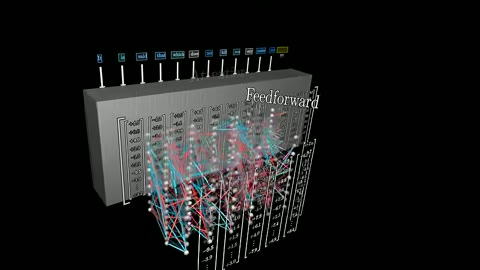
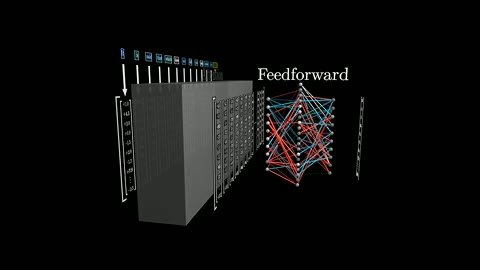
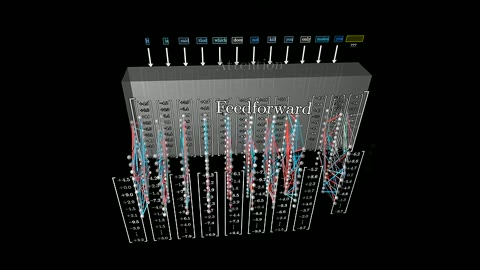

"neural network diagram"



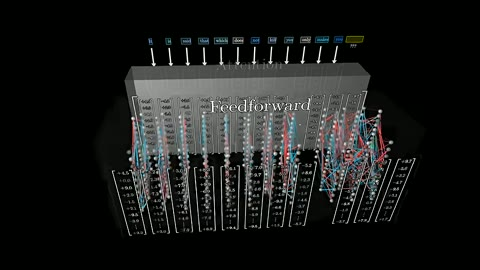
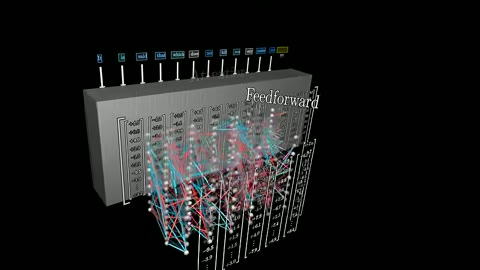
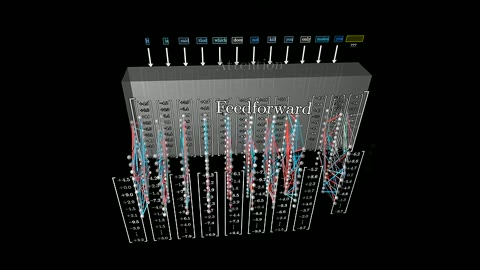

In [69]:
for words in ("a graph with arrows connecting nodes", "neural network diagram"):
    hits = qdrant.query_points(IMAGE_COLLECTION, query=embed_clip_text(words).tolist(),
                               query_filter=owner_filter([VID]), limit=3).points
    print(f'"{words}"')
    strip([(get_bytes(frame_key(VID, h.payload["idx"])), f"{mmss(h.payload['ms'] / 1000)}  score {h.score:.2f}")
           for h in hits], width=200)

## 2.7 Transcript: where the words come from

Pictures miss what people **say**, so every video gets a second, text branch. Both sources give the same shape, `[{text, t_start, t_end}]`, so everything after this treats them the same.

* **YouTube:** the captions (fast, free, already timed). SocialKit first if you have the key, otherwise yt-dlp.
* **Your own file:** no captions exist. ffmpeg pulls out the audio (mono, 16 kHz, small mp3) and OpenAI **Whisper** turns it into timed text. Whisper takes at most 25 MB per request, so long audio is sent in 20-minute pieces and the times are shifted back.

If there's no speech or no captions, the video stays searchable by its pictures. A transcript problem never fails the whole video.

In [33]:
def socialkit_cues(url, vid):
    if not SOCIALKIT_API_KEY:
        return []
    segs = (((socialkit("/youtube/transcript", {"url": url}) or {}).get("data") or {}).get("transcriptSegments")) or []
    return [{"text": s["text"].strip(), "t_start": float(s.get("start", 0)),
             "t_end": float(s.get("start", 0)) + float(s.get("duration", 0))}
            for s in segs if (s.get("text") or "").strip()]

def caption_cues(url, vid):
    """YouTube captions via yt-dlp (manual if any, else auto-generated), json3 format."""
    import yt_dlp
    for f in SCRATCH.glob(f"{vid}.*.json3"):
        f.unlink(missing_ok=True)
    opts = yt_opts(vid)
    opts.update({"skip_download": True, "writesubtitles": True, "writeautomaticsub": True,
                 "subtitleslangs": TRANSCRIPT_LANGS, "subtitlesformat": "json3"})
    try:
        with yt_dlp.YoutubeDL(opts) as ydl:
            ydl.extract_info(url, download=True)
    except Exception as exc:
        print(f"captions: {type(exc).__name__}: {str(exc)[:120]}")
        return []
    files = [SCRATCH / f"{vid}.{lang}.json3" for lang in TRANSCRIPT_LANGS] + sorted(SCRATCH.glob(f"{vid}.*.json3"))
    for f in files:
        if f.exists():
            cues = []
            for ev in json.loads(f.read_text(encoding="utf-8", errors="replace")).get("events", []):
                text = "".join(s.get("utf8", "") for s in ev.get("segs") or []).strip()
                if text:
                    t0 = ev.get("tStartMs", 0) / 1000
                    cues.append({"text": text, "t_start": t0, "t_end": t0 + ev.get("dDurationMs", 0) / 1000})
            for g in SCRATCH.glob(f"{vid}.*.json3"):
                g.unlink(missing_ok=True)
            if cues:
                return cues
    return []

_CUES_CACHE = {}    # vid → captions, so the demo below and the transcript task ask YouTube only once

def youtube_cues(url, vid):
    if vid not in _CUES_CACHE:
        cues = socialkit_cues(url, vid)
        if not cues:
            if SOCIALKIT_API_KEY:
                print("SocialKit had no captions, trying yt-dlp")
            cues = caption_cues(url, vid)
        if not cues:
            return []                      # don't remember a failure: the task's retry should really retry
        _CUES_CACHE[vid] = cues
    return [dict(c) for c in _CUES_CACHE[vid]]

def asr_cues(path):
    """Your own file → audio → Whisper. [] if the file has no audio."""
    tmp = Path(tempfile.mkdtemp())
    def audio(dst, start=None, dur=None):
        cmd = ["ffmpeg", "-nostdin", "-y", "-loglevel", "error"]
        cmd += ["-ss", f"{start:.3f}"] if start else []
        cmd += ["-t", f"{dur:.3f}"] if dur else []
        subprocess.run(cmd + ["-i", str(path), "-vn", "-ac", "1", "-ar", "16000", "-b:a", "64k", str(dst)],
                       check=True, capture_output=True)
        return dst
    try:
        full = audio(tmp / "audio.mp3")
    except subprocess.CalledProcessError:
        print("no audio track: pictures only")
        return []
    try:
        if full.stat().st_size <= 24 * 1024 * 1024:
            return whisper_segments(full)
        cues, start, dur = [], 0.0, ffprobe(path)["duration"]
        while start < dur:                                # 20-minute windows
            cues += whisper_segments(audio(tmp / f"w{int(start)}.mp3", start, min(1200, dur - start)), offset=start)
            start += 1200
        return cues
    finally:
        shutil.rmtree(tmp, ignore_errors=True)

In [34]:
CUES = youtube_cues(VIDEOS[VID]["url"], VID)
print(f"{len(CUES)} caption lines. The first few:")
table([[mmss(c["t_start"]), c["text"]] for c in CUES[:6]], ["time", "text"])

[socialkit] HTTPError: HTTP Error 503: Service Unavailable
SocialKit had no captions, trying yt-dlp


ERROR: [youtube] LPZh9BOjkQs: Sign in to confirm you’re not a bot. This helps protect our community. Use --cookies-from-browser or --cookies for the authentication. See  https://github.com/yt-dlp/yt-dlp/wiki/FAQ#how-do-i-pass-cookies-to-yt-dlp  for how to manually pass cookies. Also see  https://github.com/yt-dlp/yt-dlp/wiki/Extractors#exporting-youtube-cookies  for tips on effectively exporting YouTube cookies


captions: DownloadError: ERROR: [youtube] LPZh9BOjkQs: Sign in to confirm you’re not a bot. This helps protect our community. Use --cookies-from-
0 caption lines. The first few:


time,text


## 2.8 Who is speaking (Gemini, optional)

Captions say **what** was said and **when**, but not **who**. Gemini can watch a video, so we ask it for a short **speaker-change list**, not a transcript:

```
00:01:12 | Grant Sanderson | so the thing that a large language model
```

* We never use Gemini's words as the transcript. We match each line's first words against our captions to put the name on the right caption line. The text stays exactly as captioned.
* Long videos are cut into 10-minute windows. The first window learns the names. The rest run in parallel with those names pinned, so spellings don't drift.
* Near-identical spellings ("Pawel Hurel" / "Pawel Huryn") are merged.
* No key, or any error: the transcript just has no names. It never fails the video.

In [35]:
DIARIZE_PROMPT = """You are given a segment of a video, from {start} to {end}. Your ONLY job is to produce a compact SPEAKER-CHANGE INDEX for that segment — absolutely NOT a transcript.
{names_line}
Output one line for EVERY point in the segment where the person speaking changes:

HH:MM:SS | Speaker Full Name | first words of that turn, verbatim

Rules:
- HARD LIMIT: at most 10 words after the second |.
- Timestamps are ABSOLUTE positions in the full video (between {start} and {end}), strictly increasing.
- Output ONLY these lines. No transcript, no summary, no markdown.
- Spell each speaker's name IDENTICALLY on every line.
- Skip brief interjections (under ~3 words) that don't take over the conversation.
- Include the speaker who is ALREADY talking when the segment begins, as the first line.
"""
NAMES_KNOWN = "The speakers in this video are: {names}. Use EXACTLY these names.\n"
NAMES_UNKNOWN = ("Identify each speaker's REAL FULL NAME (introductions, on-screen text and the title help).{hints} "
                 "If a name never appears, use \"Speaker 1\", \"Speaker 2\", consistently.\n")
MAP_LINE = re.compile(r"^\s*(\d{1,2}):(\d{2})(?::(\d{2}))?\s*\|\s*([^|]{1,60}?)\s*\|\s*(.+?)\s*$")
_DIARIZE_CACHE = {}     # vid → speaker turns, so re-running a cell doesn't pay Gemini twice

def hms(s):
    s = int(s)
    return f"{s // 3600:02d}:{s % 3600 // 60:02d}:{s % 60:02d}"

def norm_word(w):
    return re.sub(r"[^a-z0-9']", "", w.lower())

def gemini_ref(row, path):
    """What Gemini watches: the YouTube URL directly, or the file uploaded to Gemini's Files API."""
    if row["source"] == "youtube":
        return row["url"]
    from google import genai
    client = genai.Client(api_key=GEMINI_API_KEY)
    f = client.files.upload(file=str(path))
    for _ in range(200):                                   # Gemini processes video before it can be read
        if getattr(f.state, "name", str(f.state)) == "ACTIVE":
            return f
        if getattr(f.state, "name", "") == "FAILED":
            raise RuntimeError("Gemini couldn't process the file")
        time.sleep(3)
        f = client.files.get(name=f.name)
    raise RuntimeError("Gemini file never became ready")

def gemini_speaker_lines(ref, start_s, end_s, names, hints=""):
    """One window of the video → Gemini's 'HH:MM:SS | Name | first words' lines."""
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=GEMINI_API_KEY)
    fd = (types.FileData(file_uri=ref) if isinstance(ref, str)
          else types.FileData(file_uri=ref.uri, mime_type=ref.mime_type))
    video = types.Part(file_data=fd, video_metadata=types.VideoMetadata(
        start_offset=f"{start_s}s", end_offset=f"{end_s}s"))
    names_line = NAMES_KNOWN.format(names=", ".join(names)) if names else NAMES_UNKNOWN.format(hints=hints)
    prompt = DIARIZE_PROMPT.format(start=hms(start_s), end=hms(end_s), names_line=names_line)
    for attempt in range(3):
        try:
            resp = client.models.generate_content(
                model=DIARIZE_MODEL, contents=types.Content(parts=[video, types.Part(text=prompt)]),
                config=types.GenerateContentConfig(temperature=0.0, max_output_tokens=8192,
                                                   thinking_config=types.ThinkingConfig(thinking_budget=0)))
            return resp.text or ""
        except Exception as exc:
            if attempt == 2:
                raise
            print(f"Gemini window {start_s}-{end_s}s: {type(exc).__name__}, retrying in {20 * 2 ** attempt}s")
            time.sleep(20 * 2 ** attempt)

def parse_lines(raw, lo, hi):
    turns = []
    for line in raw.splitlines():
        m = MAP_LINE.match(line)
        if not m:
            continue
        a, b, c, name, opening = m.groups()
        ts = (int(a) * 60 + int(b)) * 60 + int(c) if c else int(a) * 60 + int(b)
        if lo - 30 <= ts <= hi + 30:
            turns.append({"claim_s": float(ts), "speaker": name.strip(), "opening": opening})
    return turns

def merge_spellings(turns):
    import difflib
    from collections import Counter
    counts = Counter(t["speaker"] for t in turns)
    canon = {}
    for name in sorted(counts, key=counts.get, reverse=True):
        if name in canon:
            continue
        canon[name] = name
        for other in counts:
            if other not in canon and difflib.SequenceMatcher(None, name.casefold(), other.casefold()).ratio() >= 0.8:
                canon[other] = name
    for t in turns:
        t["speaker"] = canon[t["speaker"]]
    return turns

def speaker_turns(row, path, duration):
    ref = gemini_ref(row, path)
    windows = [(s, min(s + 600 + 15, int(duration) + 1)) for s in range(0, int(duration) + 1, 600)]
    hints = f' The video title is: "{row["title"]}".' if row.get("title") else ""
    turns = parse_lines(gemini_speaker_lines(ref, *windows[0], names=None, hints=hints), *windows[0])
    names = sorted({t["speaker"] for t in turns})
    with ThreadPoolExecutor(max_workers=6) as ex:
        futures = [(w, ex.submit(gemini_speaker_lines, ref, *w, names)) for w in windows[1:]]
        for w, f in futures:
            turns += parse_lines(f.result(), *w)
    seen, out = set(), []
    for t in sorted(turns, key=lambda t: t["claim_s"]):      # windows overlap by 15 s: drop repeats
        key = " ".join(norm_word(x) for x in t["opening"].split()[:8])
        if key not in seen:
            seen.add(key)
            out.append(t)
    return merge_spellings(out)

def assign_speakers(turns, cues):
    """Snap each turn to the caption line whose first words match, then label every line."""
    import bisect
    words = [[norm_word(w) for w in c["text"].split()] for c in cues]
    bounds = []
    for t in turns:
        toks = [norm_word(x) for x in t["opening"].split() if norm_word(x)][:8]
        best_i, best = None, 0
        for i, c in enumerate(cues):
            if len(toks) >= 3 and abs(c["t_start"] - t["claim_s"]) <= 150:
                score = sum(a == b for a, b in zip(toks, words[i]))
                if score > best:
                    best_i, best = i, score
        at = cues[best_i]["t_start"] if best_i is not None and best >= max(2, len(toks) // 2) else t["claim_s"]
        bounds.append((at, t["speaker"]))
    bounds.sort()
    times = [b[0] for b in bounds]
    for c in cues:
        c["speaker"] = bounds[max(bisect.bisect_right(times, c["t_start"]) - 1, 0)][1]
    return cues

def diarize_cues(cues, row, path=None):
    """→ (cues with 'speaker', sorted speaker names). Unchanged cues on no key or any error."""
    if not (GEMINI_API_KEY and cues and row.get("diarize")):
        return cues, []
    try:
        if row["id"] not in _DIARIZE_CACHE:
            _DIARIZE_CACHE[row["id"]] = speaker_turns(row, path, cues[-1]["t_end"])
        turns = _DIARIZE_CACHE[row["id"]]
        if not turns:
            return cues, []
        cues = assign_speakers(turns, [dict(c) for c in cues])
        return cues, sorted({c["speaker"] for c in cues})
    except Exception as exc:
        print(f"speaker names skipped ({type(exc).__name__}: {str(exc)[:150]})")
        return cues, []

In [36]:
if GEMINI_API_KEY: # the video sample we are running, doesnt have speaker
    t = time.time()
    LABELED, SPEAKERS = diarize_cues(CUES, VIDEOS[VID])
    print(f"speakers: {SPEAKERS}  ({time.time() - t:.0f} s)")
    table([[mmss(c["t_start"]), c.get("speaker", ""), c["text"]] for c in LABELED[:6]], ["time", "speaker", "text"])
else:
    LABELED, SPEAKERS = CUES, []
    print("No GEMINI_API_KEY: skipping speaker names. Everything else works the same.")

speakers: []  (0 s)


time,speaker,text


## 2.9 Cut the transcript into ~20-second chunks

A single caption line is too short to mean much ("and that's why"). A whole video is too long to point at a moment. About **20 seconds** is one thought, and it still has a precise start and end time to link to.

If speaker names are present, a chunk also ends when the speaker changes, so each chunk belongs to one person.

In [37]:
def chunk_cues(cues, seconds=TRANSCRIPT_CHUNK_SECONDS):
    chunks, buf, start, speaker = [], [], None, None
    last_end = cues[0]["t_end"] if cues else 0.0
    def flush():
        nonlocal buf, start, speaker
        if buf:
            chunks.append({"text": " ".join(buf), "t_start": start, "t_end": last_end,
                           **({"speaker": speaker} if speaker else {})})
        buf, start, speaker = [], None, None
    for c in cues:
        if start is not None and speaker and c.get("speaker") and c["speaker"] != speaker:
            flush()                                   # new speaker → new chunk
        if start is None:
            start, speaker = c["t_start"], c.get("speaker")
        buf.append(c["text"])
        last_end = c["t_end"]
        if last_end - start >= seconds:
            flush()
    flush()
    return chunks

CHUNKS = chunk_cues(LABELED)
print(f"{len(LABELED)} caption lines → {len(CHUNKS)} chunks")
table([[f"{mmss(c['t_start'])}–{mmss(c['t_end'])}", c.get("speaker", ""), short(c["text"])] for c in CHUNKS[:6]],
      ["time", "speaker", "text"])

0 caption lines → 0 chunks


time,speaker,text


## 2.10 The `transcript` task: two vectors per chunk

Each chunk is stored **once**, as **one point with two vectors**, in the transcript collection:

| vector | made by | good at | weak at |
|---|---|---|---|
| dense (1536 numbers) | OpenAI `text-embedding-3-small` | meaning: "how do LLMs guess the next word" finds "predicts what comes next" | exact names, numbers, code |
| sparse (BM25) | `Qdrant/bm25`, runs here, free | exact words: "GPT-3", "175 billion", a person's name | different wording for the same idea |

Searching both and merging them is called **hybrid search** (Part 5).

The timed transcript is also saved to the bucket as JSON. That lets us switch embedding models later without fetching captions from YouTube again, and the answer step reads it to see what was said around each moment.

Retries: 1. In practice the task catches its own errors and marks the video "pictures only".

In [38]:
from fastembed import SparseTextEmbedding
bm25 = SparseTextEmbedding(SPARSE_MODEL)
_bm25_lock = threading.Lock()

def sparse_docs(texts):
    with _bm25_lock:
        return [(e.indices.tolist(), e.values.tolist()) for e in bm25.embed(texts)]

def sparse_query(text):
    with _bm25_lock:
        e = next(iter(bm25.query_embed([text])))
    return e.indices.tolist(), e.values.tolist()

def chunk_point_id(vid, i):
    return str(uuid.uuid5(uuid.NAMESPACE_URL, f"{vid}:text:{i}"))

@task(name="transcript", retries=1, retry_delay_seconds=30, tags=[NB_TAG])
def t_transcript(vid, path=None):
    row = VIDEOS[vid]
    try:
        if row["source"] == "youtube":
            cues, origin = youtube_cues(row["url"], vid), "captions"
        elif path:
            cues, origin = asr_cues(path), "speech-to-text"
        else:
            return 0
        cues, speakers = diarize_cues(cues, row, path)
        chunks = chunk_cues(cues) if cues else []
        if not chunks:
            row["transcript_note"] = f"no transcript ({origin} empty): searchable by pictures only"
            print(f"{vid}: {row['transcript_note']}")
            return 0
        put_bytes(transcript_key(vid), json.dumps(chunks, ensure_ascii=False).encode())
        ensure_collection(TEXT_COLLECTION, TEXT_DIM, sparse=True)
        texts = [c["text"] for c in chunks]
        dense, sparse = embed_texts(texts), sparse_docs(texts)
        qdrant.upsert(TEXT_COLLECTION, wait=True, points=[
            qm.PointStruct(id=chunk_point_id(vid, i),
                           vector={"": d.tolist(), SPARSE_VECTOR: qm.SparseVector(indices=s[0], values=s[1])},
                           payload={"user_id": USER_ID, "video_id": vid, "modality": "text",
                                    "t_start": c["t_start"], "t_end": c["t_end"], "ms": int(c["t_start"] * 1000),
                                    "text": c["text"], **({"speaker": c["speaker"]} if c.get("speaker") else {}),
                                    "embed_version": f"{TEXT_EMBED_MODEL}-v1"})
            for i, (c, d, s) in enumerate(zip(chunks, dense, sparse))])
        row["chunks"], row["transcript_note"] = len(chunks), None
        print(f"{vid}: {len(chunks)} transcript chunks indexed ({origin}"
              f"{', speakers: ' + ', '.join(speakers) if speakers else ''})")
        return len(chunks)
    except Exception as exc:
        row["transcript_note"] = f"transcript failed ({type(exc).__name__}): searchable by pictures only"
        print(f"{vid}: {row['transcript_note']}: {str(exc)[:200]}")
        return 0

In [39]:
n = t_transcript(VID, PATH)
Path(PATH).unlink(missing_ok=True)          # the scratch copy is no longer needed

p = qdrant.scroll(TEXT_COLLECTION, scroll_filter=owner_filter([VID]), limit=1, with_vectors=True)[0][0]
print(f"\nOne transcript point ({mmss(p.payload['t_start'])}): \"{short(p.payload['text'], 80)}\"")
print(f"  dense vector : {len(p.vector[''])} numbers")
print(f"  BM25 vector  : {len(p.vector[SPARSE_VECTOR].indices)} non-zero entries (one per distinct word)")
print(f"  bucket copy  : {transcript_key(VID)}")

INFO:prefect.task_runs:Finished in state Completed()


yt_LPZh9BOjkQs: 21 transcript chunks indexed (captions, speakers: Grant Sanderson)

One transcript point (01:48): "You can think of training a little bit like tuning the dials on a big machine. …"
  dense vector : 1536 numbers
  BM25 vector  : 32 non-zero entries (one per distinct word)
  bucket copy  : notebook/yt_LPZh9BOjkQs/transcript.json


# Part 3. Scaling the storage

A RAG demo with 10 documents works with anything. We need it to keep working with **100,000 videos**, which can mean tens of millions of vectors. Here are the four choices that make that possible, measured on the video you just added.

## 3.1 Store fewer vectors

The cheapest vector is the one you never make. You already saw this in 2.2–2.3 (one frame every 2 s, repeats dropped). Here's what it saved on this video:

In [40]:
every = int(INFO["duration"] * INFO["fps"])
sampled, kept = SAMPLE_COUNTS[VID]
table([
    ["every frame",                f"{every:,}", "what a naive pipeline would embed"],
    ["one every 2 s",              f"{sampled:,}", f"{every / sampled:.0f}x fewer"],
    ["after dropping repeats",     f"{kept:,}", f"{every / kept:.0f}x fewer than every frame"],
    ["transcript chunks (~20 s)",  f"{VIDEOS[VID]['chunks']:,}", "the whole speech, in a handful of points"],
], ["what we'd store", "vectors", "note"])

what we'd store,vectors,note
every frame,"14,325",what a naive pipeline would embed
one every 2 s,239,60x fewer
after dropping repeats,155,92x fewer than every frame
transcript chunks (~20 s),21,"the whole speech, in a handful of points"


## 3.2 RAM: full vectors on disk, a small copy in RAM

Vector search is fast when the vectors are in RAM, but RAM is the expensive part of a vector database. So each collection is set up like this:

```
              RAM                                   DISK
  ┌──────────────────────────────┐      ┌─────────────────────────────────┐
  │ int8 copy of every vector    │      │ full float32 vectors (4x bigger)│
  │ (1 byte per number)          │      │ HNSW search graph               │
  │  → does the fast search      │      │  → read only for the top few    │
  └──────────────────────────────┘      └─────────────────────────────────┘
```

1. The search runs on the small int8 copies in RAM and finds the best candidates.
2. **Rescore**: Qdrant reads the full vectors of just those candidates from disk and re-sorts them exactly.

That gives about 4× less RAM for nearly the same results. Here's the math with this video's real numbers, scaled up to 10-minute videos:

In [41]:
per_min_frames = kept / (INFO["duration"] / 60)
per_min_chunks = VIDEOS[VID]["chunks"] / (INFO["duration"] / 60)
rows = []
for videos in (1_000, 10_000, 100_000):
    f = videos * 10 * per_min_frames                     # frame vectors (768 numbers)
    c = videos * 10 * per_min_chunks                     # transcript vectors (1536 numbers)
    full = f * IMAGE_DIM * 4 + c * TEXT_DIM * 4          # float32 = 4 bytes per number
    int8 = f * IMAGE_DIM * 1 + c * TEXT_DIM * 1          # int8    = 1 byte per number
    rows.append([f"{videos:,}", f"{f + c:,.0f}", f"{full / 1e9:,.1f} GB", f"{int8 / 1e9:,.1f} GB"])
table(rows, ["10-min videos", "vectors", "all in RAM (float32)", "our RAM (int8 only)"])
print("(vectors only; the HNSW graph adds some more, and it lives on disk too)")

10-min videos,vectors,all in RAM (float32),our RAM (int8 only)
"1,000","221,143",0.8 GB,0.2 GB
"10,000","2,211,433",7.6 GB,1.9 GB
"100,000","22,114,333",76.0 GB,19.0 GB


(vectors only; the HNSW graph adds some more, and it lives on disk too)


**Does int8 lose accuracy?** We can check on this video's frames: quantize the vectors to int8 the way our collection does (over the full range of values), search with a question, and compare with the exact result.

In [42]:
pts, _ = qdrant.scroll(IMAGE_COLLECTION, scroll_filter=owner_filter([VID]), limit=10_000, with_vectors=True)
V = np.array([p.vector for p in pts], dtype=np.float32)
q = embed_clip_text("a diagram of a neural network")

lo, hi = float(V.min()), float(V.max())                    # Qdrant's default: the full range of values
V8 = np.round((np.clip(V, lo, hi) - lo) / (hi - lo) * 255).astype(np.uint8)
approx = (V8.astype(np.float32) / 255 * (hi - lo) + lo) @ q
exact = V @ q

top = lambda scores, k=10: list(np.argsort(-scores)[:k])
true10 = top(exact)
int8_10 = top(approx)
cands = top(approx, 30)                                     # rescore: re-sort the top 30 with full vectors
rescored10 = sorted(cands, key=lambda i: -exact[i])[:10]
print(f"memory      : float32 {V.nbytes / 1024:.0f} KB → int8 {V8.nbytes / 1024:.0f} KB")
print(f"top-10 with int8 alone        : {len(set(int8_10) & set(true10))}/10 same as exact, "
      f"same order: {int8_10 == true10}")
print(f"top-10 with int8 + rescore    : {len(set(rescored10) & set(true10))}/10 same as exact, "
      f"same order: {rescored10 == true10}")
if not QDRANT_URL:
    print("\n(Local Qdrant in Colab always searches exactly and ignores these settings. "
          "Qdrant Cloud or a server applies them.)")
else:
    print("\nYour Qdrant Cloud collection:", qdrant.get_collection(IMAGE_COLLECTION).config.quantization_config)

memory      : float32 465 KB → int8 116 KB
top-10 with int8 alone        : 10/10 same as exact, same order: False
top-10 with int8 + rescore    : 10/10 same as exact, same order: True

(Local Qdrant in Colab always searches exactly and ignores these settings. Qdrant Cloud or a server applies them.)


## 3.3 One collection for everyone, filtered by owner

The obvious design is one collection per user. With 10,000 users that's 10,000 collections, each with its own index and overhead. Instead:

* **One shared collection.** Every point carries `user_id`.
* `user_id` has a **tenant index**, so Qdrant stores each user's points together and a search only touches that user's slice.
* **Every** search and delete goes through `owner_filter()`, so nobody can see another user's videos. Asking for "only these videos" is just one more condition (`video_id` in a list).

Here's the same question searched as you and as another user:

In [43]:
qv = embed_clip_text("a diagram of a neural network").tolist()
for who in (USER_ID, "someone-else"):
    hits = qdrant.query_points(IMAGE_COLLECTION, query=qv, query_filter=owner_filter(user_id=who), limit=5).points
    print(f"searching as {who!r:16}: {len(hits)} results")

searching as 'notebook'      : 5 results
searching as 'someone-else'  : 0 results


## 3.4 Re-running is safe

A point's id is made from `video_id:frame_number`, so the same frame always gets the same id. Writing it again **replaces** it. That's why a Prefect retry never leaves duplicate points behind. Here we write every frame point of this video again:

In [44]:
print("id of frame 0:", point_id(VID, 0), " (same every time)")
before = qdrant.count(IMAGE_COLLECTION, count_filter=owner_filter([VID]), exact=True).count
qdrant.upsert(IMAGE_COLLECTION, wait=True,
              points=[qm.PointStruct(id=p.id, vector=p.vector, payload=p.payload) for p in pts])
after = qdrant.count(IMAGE_COLLECTION, count_filter=owner_filter([VID]), exact=True).count
print(f"points before: {before}, after writing them all again: {after}")

id of frame 0: 16b511be-b472-5b99-947d-5f3a390f0c47  (same every time)
points before: 155, after writing them all again: 155


Two more choices you've already seen:
* **Small payloads.** Points carry only what search filters or displays: owner, video, time, frame number and chunk text. Titles and URLs live in Postgres and are joined when the answer is built.
* **The bucket holds the bytes.** Thumbnails and transcripts live in object storage, which is cheap and has no size limit. Qdrant holds only vectors.

# Part 4. Running it for real

In Part 2 we called each task by hand to look inside it, and Part 3 showed where their vectors go. The product never calls tasks one by one: its worker runs the whole **flow** for every video, and Prefect handles retries and records every run.

* **4.1** runs this video through the flow, exactly like one of your videos, and links to the run.
* **4.2** shows how many videos from many users share the workers fairly.


**The flow.** The four tasks together. This is what the product's worker runs for every video. 4.1 runs it on this video; Part 6 runs it on yours.

* If a task fails for good, the flow marks the video `failed` with the reason and re-raises the error, so Prefect marks the run Failed too.
* The scratch file is always deleted, even on failure.

In [45]:
@flow(name="ms-ingest-video", log_prints=True, timeout_seconds=3600)
def ingest_video(vid):
    VIDEOS[vid]["attempts"] += 1
    path = None
    try:
        path = t_fetch(vid)
        if not path:                                  # duplicate: already marked skipped
            return {"video_id": vid, "skipped": True}
        frames = t_sample(vid, path)
        n = t_embed_index(vid, frames)
        t = t_transcript(vid, path)
        print(f"{vid} indexed: {n} frames + {t} transcript chunks")
        return {"video_id": vid, "frames": n, "transcript_chunks": t}
    except Exception as exc:
        set_status(vid, "failed", error=f"{type(exc).__name__}: {exc}")
        raise
    finally:
        if path:
            Path(path).unlink(missing_ok=True)

## 4.1 The real Prefect run

Now this video goes through the whole flow, for real, the way the worker runs every video.

* It downloads, samples, embeds and transcribes again, exactly like one of your videos would.
* The vectors land on the same ids as before, so nothing is duplicated.
* You get one flow run with its tasks underneath, and a link straight to it.


In [ ]:
from prefect.client.orchestration import get_client
from prefect.client.schemas.filters import (FlowRunFilter, FlowRunFilterId, TaskRunFilter,
                                            TaskRunFilterStartTime, TaskRunFilterTags)

def prefect_task_runs(since=None, expect=1, flow_run_id=None):
    """This notebook's task runs (after `since`, or inside one flow run), read back from Prefect's API.
    Prefect records runs in the background, so wait (up to 20 s) until they have all landed and finished."""
    flt = TaskRunFilter(tags=TaskRunFilterTags(all_=[NB_TAG]),
                        start_time=TaskRunFilterStartTime(after_=since) if since else None)
    frf = FlowRunFilter(id=FlowRunFilterId(any_=[flow_run_id])) if flow_run_id else None
    for _ in range(20):
        with get_client(sync_client=True) as client:
            runs = client.read_task_runs(flow_run_filter=frf, task_run_filter=flt, limit=200)
        if len(runs) >= expect and all(r.state and r.state.is_final() for r in runs):
            break
        time.sleep(1)
    runs.sort(key=lambda r: r.start_time or datetime.max.replace(tzinfo=timezone.utc))
    table([[r.name, r.state.name if r.state else "", r.run_count,
            f"{r.total_run_time.total_seconds():.1f} s" if r.total_run_time else ""] for r in runs],
          ["task run", "state", "attempts", "time"])

state = ingest_video(VID, return_state=True)
run_id = state.state_details.flow_run_id
print(f"\nflow run: {state.name}\n")
prefect_task_runs(expect=4, flow_run_id=run_id)
print("\nvideo table:")
timeline(VID)
if PREFECT_API_URL:
    from prefect.settings import PREFECT_UI_URL
    print("\nOpen this run in Prefect Cloud:", f"{PREFECT_UI_URL.value()}/runs/flow-run/{run_id}")


**A retry, live.** This task fails on its first attempt and works on the second, the way a download does when the network hiccups. Prefect waits 2 seconds and runs it again. You see `attempts: 2` and a final state of `Completed`.

In [47]:
_calls = {"n": 0}

@task(name="flaky-download", retries=2, retry_delay_seconds=2, tags=[NB_TAG])
def flaky_download():
    _calls["n"] += 1
    if _calls["n"] == 1:
        raise ConnectionError("network blip")
    return "downloaded"

since = datetime.now(timezone.utc)
print("result:", flaky_download())
prefect_task_runs(since, expect=1)

INFO:prefect.task_runs:Task run failed with exception: ConnectionError('network blip') - Retry 1/2 will start 2 second(s) from now
INFO:prefect.task_runs:Finished in state Completed()


result: downloaded


task run,state,attempts,time
flaky-download,Completed,2,0.0 s


## 4.2 Scaling the processing: a fair queue in front of Prefect

If the API sent every new video straight to Prefect, Prefect would run them in the order they arrived. One user who adds 50 videos would make everyone else wait behind all 50.

So in the product, new videos wait as `pending` in Postgres, and a small **dispatcher** loop runs every 3 seconds:
1. It counts how many videos are processing right now.
2. It fills the free slots (`DISPATCH_MAX_INFLIGHT`) **round-robin across users**: everyone's oldest video first, then everyone's second, and so on.
3. It hands those videos to Prefect.

The claim is one SQL `UPDATE … WHERE status='pending'`, so two workers can never take the same video. More workers means more slots.

Here's the difference, simulated. Alice adds 6 videos, then Bob adds 1 and Chen adds 2:

In [48]:
arrivals = [("alice", f"alice-{i}") for i in range(1, 7)] + [("bob", "bob-1"), ("chen", "chen-1"), ("chen", "chen-2")]

def fifo(queue):
    return [v for _, v in queue]

def fair(queue):
    per_user = {}
    for user, v in queue:
        per_user.setdefault(user, []).append(v)
    order, rnd = [], 0
    while any(len(vs) > rnd for vs in per_user.values()):
        order += [vs[rnd] for vs in per_user.values() if len(vs) > rnd]
        rnd += 1
    return order

for name, order in (("first come, first served", fifo(arrivals)), ("fair (what we do)", fair(arrivals))):
    batches = [order[i:i + DISPATCH_MAX_INFLIGHT] for i in range(0, len(order), DISPATCH_MAX_INFLIGHT)]
    print(f"{name}:")
    for i, b in enumerate(batches, 1):
        print(f"   slot round {i}: {', '.join(b)}")
    print(f"   Bob's video starts in round {next(i for i, b in enumerate(batches, 1) if 'bob-1' in b)}\n")

first come, first served:
   slot round 1: alice-1, alice-2
   slot round 2: alice-3, alice-4
   slot round 3: alice-5, alice-6
   slot round 4: bob-1, chen-1
   slot round 5: chen-2
   Bob's video starts in round 4

fair (what we do):
   slot round 1: alice-1, bob-1
   slot round 2: chen-1, alice-2
   slot round 3: chen-2, alice-3
   slot round 4: alice-4, alice-5
   slot round 5: alice-6
   Bob's video starts in round 1



# Part 5. Answering a question

```
 question
    │
    ├─► CLIP text vector ────► pictures collection ──────────────┐
    ├─► OpenAI vector ───────► transcript (dense)  ─┐            │
    └─► BM25 vector ─────────► transcript (BM25)   ─┴─► merge ───┤      5.1 / 5.2
                                                                 ▼
                                    group hits within 15 s into "moments"             5.3
                                    (found by picture AND speech → ×1.5)
                                                                 ▼
                                    reranker re-reads question + transcript           5.4
                                                                 ▼
             CHECK 1  is the best match good enough? ── no ──► "couldn't find it"     5.5
                                                                 │ yes  (no LLM call)
                                                                 ▼
                       LLM sees top 6: frame + transcript + what was said around it   5.6
                                                                 ▼
             CHECK 2  the prompt: answer only from the moments, else say "not found"
             CHECK 3  remove any [n] citation that points at nothing                  5.7
                                                                 ▼
                                    answer + clickable moments
```

How we avoid making things up, in short:
1. **Don't call the LLM** when nothing matches well.
2. **Make the LLM cite.** Every claim gets an `[n]` that points at a real frame or transcript chunk you can open.
3. **Check the citations** in code afterwards, and treat an answer with no citations as "not found".

In [49]:
QUESTION = "What does a large language model actually predict?"

## 5.1 Three searches at once

The question is turned into three vectors and searched three ways, **in parallel**. The slowest one (the OpenAI call, about 0.3 s) hides the others. Each search is filtered by owner, and by `video_ids` if you chose videos.

In [50]:
def search_points(collection, query, video_ids=None, limit=BRANCH_TOP_K, using=None, user_id=None):
    try:
        hits = qdrant.query_points(
            collection_name=collection, query=query, using=using, limit=limit, with_payload=True,
            query_filter=owner_filter(video_ids, user_id),
            # dense searches use the int8 copy, then re-check the top hits with full vectors
            search_params=qm.SearchParams(quantization=qm.QuantizationSearchParams(rescore=True))
            if (using is None and QDRANT_QUANTIZATION) else None).points
    except Exception as exc:
        if "not found" in str(exc).lower() or "doesn't exist" in str(exc).lower():
            return []                                   # nothing indexed yet
        raise
    return [{"score": float(h.score), **(h.payload or {})} for h in hits]

def search_three(question, video_ids=None):
    def words():
        idx, val = sparse_query(question)
        return search_points(TEXT_COLLECTION, qm.SparseVector(indices=idx, values=val), video_ids, using=SPARSE_VECTOR)
    jobs = [
        lambda: search_points(IMAGE_COLLECTION, embed_clip_text(question).tolist(), video_ids),
        lambda: search_points(TEXT_COLLECTION, embed_texts([question])[0].tolist(), video_ids),
        words,
    ]
    with ThreadPoolExecutor(max_workers=3) as ex:
        return list(ex.map(lambda f: f(), jobs))           # pictures, meaning, exact words

three searches in 0.23 s

pictures (CLIP cosine):



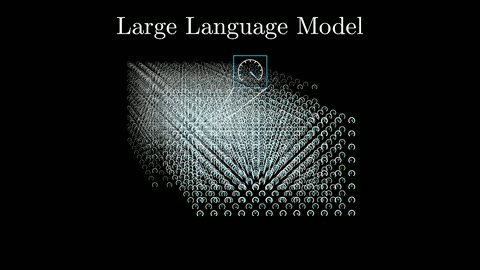
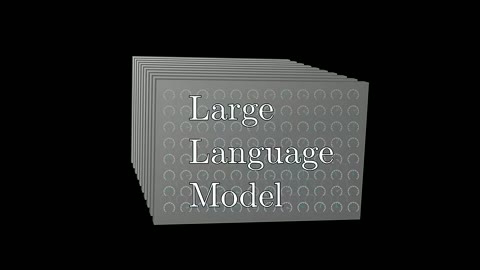
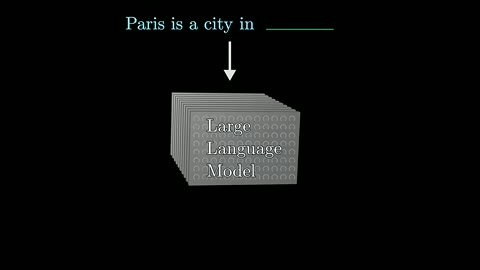
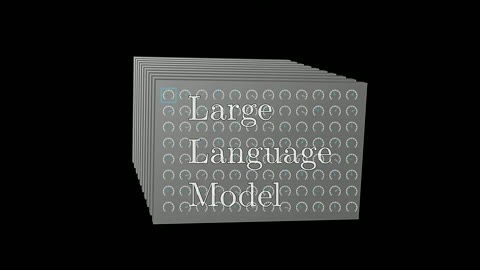
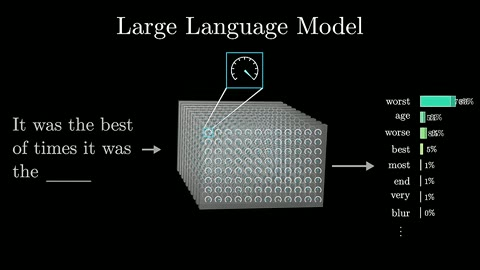

meaning (OpenAI cosine):


time,score,text
01:48,0.670,You can think of training a little bit like tuning the dials on a big machine. The way that a langu…
02:55,0.666,"When you do this for many, many trillions of examples, not only does the model start to give more a…"
06:37,0.644,based on how those hundreds of billions of parameters are tuned during training. This makes it incr…
00:21,0.520,"You could then finish the script by feeding in what you have to the machine, seeing what it would p…"


exact words (BM25, no fixed scale):


time,score,text
06:37,5.980,based on how those hundreds of billions of parameters are tuned during training. This makes it incr…
02:55,5.890,"When you do this for many, many trillions of examples, not only does the model start to give more a…"
00:21,5.850,"You could then finish the script by feeding in what you have to the machine, seeing what it would p…"
03:19,5.390,"To illustrate, imagine that you could perform one billion additions and multiplications every singl…"


In [51]:
t = time.time()
VHITS, DHITS, SHITS = search_three(QUESTION, video_ids=[VID])
print(f"three searches in {time.time() - t:.2f} s\n")

print("pictures (CLIP cosine):")
strip([(get_bytes(frame_key(h["video_id"], h["idx"])), f"{mmss(h['ms'] / 1000)}  {h['score']:.2f}") for h in VHITS[:5]], width=150)
print("meaning (OpenAI cosine):")
table([[mmss(h["t_start"]), round(h["score"], 3), short(h["text"])] for h in DHITS[:4]], ["time", "score", "text"])
print("exact words (BM25, no fixed scale):")
table([[mmss(h["t_start"]), round(h["score"], 2), short(h["text"])] for h in SHITS[:4]], ["time", "score", "text"])

## 5.2 Merge the two transcript lists (hybrid search)

Cosine scores (~0.3–0.5) and BM25 scores (a few points, up to ~20) are on different scales, so we can't add them. We merge by **rank** instead, which is called **Reciprocal Rank Fusion**: each list gives a chunk `1 / (60 + rank)` points.
* A chunk that both lists found rises to the top.
* A chunk only BM25 found, like an exact name the embedding blurred, still gets in on its rank.

In [52]:
def merge_text(dense, sparse):
    if not sparse:
        return dense
    if not dense:
        return [{**h, "sparse_score": h["score"], "score": 0.0} for h in sparse][:BRANCH_TOP_K]
    acc = {}
    for rank, h in enumerate(dense):
        acc[(h["video_id"], h["ms"])] = {"hit": dict(h), "rrf": 1 / (RRF_K + rank)}
    for rank, h in enumerate(sparse):
        k = (h["video_id"], h["ms"])
        if k in acc:
            acc[k]["rrf"] += 1 / (RRF_K + rank)
            acc[k]["hit"]["sparse_score"] = h["score"]
        else:   # BM25-only: keep cosine at 0 so a BM25 number never meets a cosine threshold
            acc[k] = {"hit": {**h, "sparse_score": h["score"], "score": 0.0}, "rrf": 1 / (RRF_K + rank)}
    return [x["hit"] for x in sorted(acc.values(), key=lambda x: -x["rrf"])][:BRANCH_TOP_K]

THITS = merge_text(DHITS, SHITS)
table([[mmss(h["t_start"]), round(h["score"], 3), round(h.get("sparse_score", 0), 2),
        "both" if h["score"] and h.get("sparse_score") else ("meaning" if h["score"] else "words"), short(h["text"], 80)]
       for h in THITS[:6]], ["time", "cosine", "bm25", "found by", "text"])

time,cosine,bm25,found by,text
06:37,0.644,5.980,both,based on how those hundreds of billions of parameters are tuned during training…
02:55,0.666,5.890,both,"When you do this for many, many trillions of examples, not only does the model …"
01:48,0.670,5.260,both,You can think of training a little bit like tuning the dials on a big machine. …
00:21,0.520,5.850,both,"You could then finish the script by feeding in what you have to the machine, se…"
03:19,0.495,5.390,both,"To illustrate, imagine that you could perform one billion additions and multipl…"
04:28,0.473,2.420,both,"However, not all language models can be easily parallelized. Prior to 2017, mos…"


## 5.3 Group into moments: pictures + speech

Now we combine frames and transcript. Hits from the same video **within 15 seconds** of each other are one **moment**. A moment's score is its best frame's rank score plus its best transcript chunk's rank score.

If **both** a frame and the speech point at the same moment, that's two independent signals agreeing, so the moment gets **×1.5**. We only count the best hit of each kind per moment, so a burst of near-identical frames can't outvote a real match.

In [53]:
def fuse(visual_hits, text_hits):
    ranked = [{**h, "modality": "frame", "rrf": 1 / (RRF_K + r), "t": h["ms"] / 1000} for r, h in enumerate(visual_hits)]
    ranked += [{**h, "modality": "text", "rrf": 1 / (RRF_K + r), "t": h["t_start"]} for r, h in enumerate(text_hits)]
    windows = []
    for h in sorted(ranked, key=lambda x: -x["rrf"]):
        w = next((w for w in windows if w["video_id"] == h["video_id"] and abs(w["t"] - h["t"]) <= FUSION_WINDOW_S), None)
        if w is None:
            w = {"video_id": h["video_id"], "t": h["t"], "modalities": set(), "frame": None, "text": None}
            windows.append(w)
        w["modalities"].add(h["modality"])
        w[h["modality"]] = w[h["modality"]] or h            # keep the best hit of each kind
    for w in windows:
        w["rrf"] = (w["frame"]["rrf"] if w["frame"] else 0) + (w["text"]["rrf"] if w["text"] else 0)
        if len(w["modalities"]) == 2:
            w["rrf"] *= CROSS_MODAL_BOOST
    return sorted(windows, key=lambda w: -w["rrf"])

FUSED = fuse(VHITS, THITS)
print(f"{len(VHITS)} frame hits + {len(THITS)} transcript hits → {len(FUSED)} moments\n")
table([[i, mmss(w["t"]), " + ".join(sorted(w["modalities"])), round(w["rrf"], 4), short((w["text"] or {}).get("text", "(frame only)"), 70)]
       for i, w in enumerate(FUSED[:8], 1)], ["rank", "time", "found by", "score", "transcript"])

20 frame hits + 20 transcript hits → 20 moments



rank,time,found by,score,transcript
1,01:48,frame + text,0.048,You can think of training a little bit like tuning the dials on a big…
2,00:38,frame + text,0.046,"Instead of predicting one word with certainty, though, what it does i…"
3,02:12,frame + text,0.045,they can have hundreds of billions of these parameters. No human ever…
4,01:28,frame + text,0.043,Models learn how to make these predictions by processing an enormous …
5,04:49,frame + text,0.043,"The very first step inside a transformer, and most other language mod…"
6,01:06,frame + text,0.043,"hypothetical AI assistant would say in response, and that's what's pr…"
7,00:00,frame + text,0.042,[Submit subtitle corrections at criblate.com] Imagine you happen acro…
8,06:37,text,0.017,based on how those hundreds of billions of parameters are tuned durin…


## 5.4 Rerank: read the question and the text together

Rank fusion only knows **positions**, not how relevant a hit really is. A **cross-encoder** reads the question and each moment's transcript **together** and scores how well that text answers the question. It's much sharper than comparing two separate vectors, but too slow to run on everything, so it only judges the top 30 moments.

* Final score = 70% reranker + 30% fused rank.
* Frame-only moments have no text to read. They keep their rank, scaled by how strong their picture match is.
* The reranker runs here: free, about 90 MB.

In [54]:
import math
from fastembed.rerank.cross_encoder import TextCrossEncoder
reranker = TextCrossEncoder(model_name=RERANK_MODEL)

def rerank(question, windows):
    windows = [dict(w) for w in windows]
    cand = [i for i, w in enumerate(windows) if (w.get("text") or {}).get("text")][:RERANK_TOP_K]
    if len(windows) < 2 or len(cand) < 2:
        return windows
    raw = list(reranker.rerank(question, [windows[i]["text"]["text"] for i in cand]))
    rel = {i: 1 / (1 + math.exp(-s)) for i, s in zip(cand, raw)}      # squash to 0..1
    top_rrf = max(w["rrf"] for w in windows) or 1
    for i, w in enumerate(windows):
        rr = w["rrf"] / top_rrf
        if i in rel:
            w["rerank"] = round(rel[i], 4)
            w["blend"] = RERANK_WEIGHT * rel[i] + (1 - RERANK_WEIGHT) * rr
        else:   # frame only: as strong as its picture match (0 at the gate, 1 at "strong")
            vis = (w.get("frame") or {}).get("score", 0)
            w["blend"] = rr * max(0, min(1, (vis - CONFIDENCE_THRESHOLD) / (VISUAL_STRONG - CONFIDENCE_THRESHOLD)))
    return sorted(windows, key=lambda w: -w["blend"])

RANKED = rerank(QUESTION, FUSED)
before = {(w["video_id"], w["t"]): i for i, w in enumerate(FUSED, 1)}
table([[i, before[(w["video_id"], w["t"])], mmss(w["t"]), w.get("rerank", "–"), round(w["blend"], 3),
        short((w["text"] or {}).get("text", "(frame only)"), 70)] for i, w in enumerate(RANKED[:TOP_K], 1)],
      ["new rank", "old rank", "time", "reranker 0-1", "final", "transcript"])

new rank,old rank,time,reranker 0-1,final,transcript
1,1,01:48,0.985,0.990,You can think of training a little bit like tuning the dials on a big…
2,4,01:28,0.948,0.935,Models learn how to make these predictions by processing an enormous …
3,8,06:37,0.999,0.803,based on how those hundreds of billions of parameters are tuned durin…
4,9,02:55,0.999,0.801,"When you do this for many, many trillions of examples, not only does …"
5,10,00:21,0.999,0.799,You could then finish the script by feeding in what you have to the m…
6,11,03:19,0.821,0.673,"To illustrate, imagine that you could perform one billion additions a…"


## 5.5 Check 1: is anything good enough? (no LLM yet)

Before paying for an LLM call, look at the **raw** best scores of the two kinds of search:
* best picture match ≥ **0.2** (CLIP cosine), **or**
* best transcript match ≥ **0.35** (OpenAI cosine).

If neither passes, we answer *"I couldn't find that in your videos"* straight away. This check is free, takes 0 seconds, and removes most of the risk of an invented answer: an LLM handed weak evidence tends to make something up anyway.

Below: our question, then one this video can't answer.

In [55]:
ABSTAIN = ("I couldn't find that in your videos — nothing indexed looks related to the question "
           "(neither what's on screen nor what's said).")

def gate_ok(best_visual, best_text):
    return best_visual >= CONFIDENCE_THRESHOLD or best_text >= TEXT_CONFIDENCE_THRESHOLD

OFF_TOPIC = "How long should I rest a steak after grilling it?"
v_off, d_off, _ = search_three(OFF_TOPIC, video_ids=[VID])
for q, v, d in ((QUESTION, VHITS, DHITS), (OFF_TOPIC, v_off, d_off)):     # QUESTION reuses 5.1's results
    bv, bt = (v[0]["score"] if v else 0), (d[0]["score"] if d else 0)
    print(f"Q: {q}")
    print(f"   best picture {bv:.3f} (needs {CONFIDENCE_THRESHOLD})   best transcript {bt:.3f} (needs {TEXT_CONFIDENCE_THRESHOLD})")
    print("   →", "go on to the LLM" if gate_ok(bv, bt) else "STOP: " + ABSTAIN, "\n")

Q: What does a large language model actually predict?
   best picture 0.315 (needs 0.2)   best transcript 0.670 (needs 0.35)
   → go on to the LLM 

Q: How long should I rest a steak after grilling it?
   best picture 0.188 (needs 0.2)   best transcript 0.116 (needs 0.35)
   → STOP: I couldn't find that in your videos — nothing indexed looks related to the question (neither what's on screen nor what's said). 



## 5.6 What the LLM gets to see

`retrieve()` puts 5.1 to 5.4 together and returns the top 6 moments as numbered **citations**. Then, for each moment, the LLM gets:
* **the frame**, shrunk again to at most 512 px (fewer image tokens: faster and cheaper, no loss in answer quality);
* **the transcript chunk** and the speaker's name, if known;
* **what was said 10 s before and after**, read from the transcript saved in the bucket. An answer often continues into the next chunk.

Frames and transcripts are fetched all at once on a thread pool, so this adds almost no time.

In [56]:
def frame_times(vid):
    pts, _ = qdrant.scroll(IMAGE_COLLECTION, scroll_filter=owner_filter([vid]), limit=10_000,
                           with_payload=["idx", "ms"], with_vectors=False)
    return [(p.payload["idx"], p.payload["ms"]) for p in pts]

def match_pct(w):
    """0-100 for the card: the reranker's score if it judged the moment, else the raw cosine between 'just passed' and 'strong'."""
    clamp = lambda v, lo, hi: max(0.0, min(1.0, (v - lo) / (hi - lo)))
    s = []
    if w.get("frame"):
        s.append(clamp(w["frame"]["score"], CONFIDENCE_THRESHOLD, VISUAL_STRONG))
    if w.get("text"):
        s.append(w["rerank"] if "rerank" in w else clamp(w["text"]["score"], TEXT_CONFIDENCE_THRESHOLD, TEXT_STRONG))
    return int(round(50 + max(s or [0]) * 50))

def retrieve(question, video_ids=None, top_k=TOP_K):
    vhits, dhits, shits = search_three(question, video_ids)
    fused = fuse(vhits, merge_text(dhits, shits))
    windows = rerank(question, fused)[:top_k]
    citations, nearest = [], {}
    for n, w in enumerate(windows, 1):
        vid, fr, tx = w["video_id"], w["frame"], w["text"]
        ms = int(fr["ms"]) if fr else int(w["t"] * 1000)
        idx = fr["idx"] if fr else None
        if idx is None:     # transcript-only moment: borrow the nearest frame for the card
            nearest.setdefault(vid, frame_times(vid))
            idx_preview = min(nearest[vid], key=lambda t: abs(t[1] - ms))[0] if nearest[vid] else None
        row = VIDEOS.get(vid, {})
        citations.append({
            "n": n, "video_id": vid, "title": row.get("title") or vid, "url": row.get("url"), "ms": ms,
            "timestamp": mmss(ms / 1000), "idx": idx, "preview_idx": idx if idx is not None else idx_preview,
            "t_start": tx["t_start"] if tx else ms / 1000, "t_end": tx["t_end"] if tx else ms / 1000,
            "transcript": (tx or {}).get("text"), "speaker": (tx or {}).get("speaker"),
            "modalities": sorted(w["modalities"]), "match": match_pct(w),
            "link": f"{row['url']}&t={ms // 1000}" if row.get("url") else None})
    return {"citations": citations, "candidates": len(fused),
            "best_visual": vhits[0]["score"] if vhits else 0.0,
            "best_text": dhits[0]["score"] if dhits else 0.0}

def shrink(jpeg, max_px=LLM_IMAGE_MAX_PX):
    img = Image.open(io.BytesIO(jpeg))
    if max(img.size) <= max_px:
        return jpeg
    img.thumbnail((max_px, max_px))
    buf = io.BytesIO()
    img.convert("RGB").save(buf, format="JPEG", quality=80)
    return buf.getvalue()

def context(chunks, c, pad=CONTEXT_PAD_S):
    """What was said around a moment, from the transcript copy in the bucket."""
    t0, t1 = c["t_start"], c["t_end"]
    parts = {"said just before": [], "said while this frame was on screen": [], "said just after": []}
    for ch in chunks:
        if ch["t_end"] <= t0 - pad or ch["t_start"] >= t1 + pad or ch["text"] == c.get("transcript"):
            continue
        text = f"{ch['speaker']}: {ch['text']}" if ch.get("speaker") else ch["text"]
        where = ("said just before" if ch["t_end"] <= t0 else "said just after" if ch["t_start"] >= t1
                 else "said while this frame was on screen")
        parts[where].append(text)
    return [(k, " ".join(v)) for k, v in parts.items() if v]

def build_moments(citations):
    def frame(c):
        return get_bytes(frame_key(c["video_id"], c["idx"])) if c["idx"] is not None else None
    def transcript(vid):
        try:
            return json.loads(get_bytes(transcript_key(vid)))
        except Exception:
            return []
    vids = sorted({c["video_id"] for c in citations})
    with ThreadPoolExecutor(max_workers=16) as ex:
        images = list(ex.map(frame, citations))
        chunks = dict(zip(vids, ex.map(transcript, vids)))
    return [{"image": img, "transcript": c["transcript"], "speaker": c["speaker"], "timestamp": c["timestamp"],
             "context": context(chunks[c["video_id"]], c), **({"parts": c["parts"]} if c.get("parts") else {})}
            for img, c in zip(images, citations)]

20 candidate moments → top 6




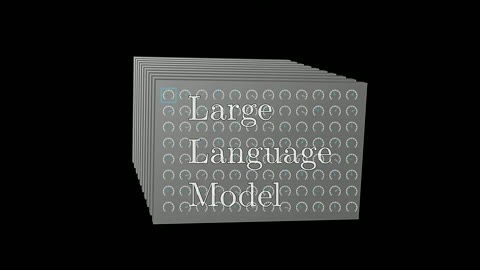
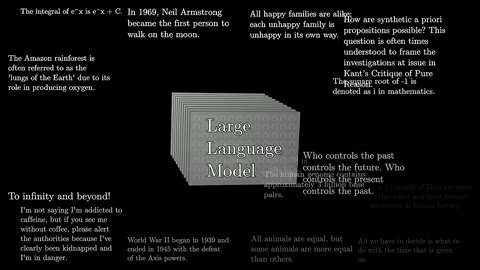

[1] @ 01:48
  transcript: You can think of training a little bit like tuning the dials on a big machine. The way that a language model behaves is…
  said just before: Grant Sanderson: Models learn how to make these predictions by processing an enormous amount of text, typically pulled …
  said just after: Grant Sanderson: they can have hundreds of billions of these parameters. No human ever deliberately sets those paramete…


In [57]:
R = retrieve(QUESTION, video_ids=[VID])
MOMENTS = build_moments(R["citations"])
print(f"{R['candidates']} candidate moments → top {len(MOMENTS)}\n")
strip([(shrink(m["image"]), f"[{i}] {m['timestamp']}") for i, m in enumerate(MOMENTS, 1) if m["image"]], width=150)
m = MOMENTS[0]
print(f"[1] @ {m['timestamp']}\n  transcript: {short(m['transcript'], 120)}")
for where, text in m["context"]:
    print(f"  {where}: {short(text, 120)}")

## 5.7 The answer, and checks 2 and 3

**Check 2: the prompt.** The system prompt (below, the product's exact text) tells the model to:
* use only the numbered moments;
* cite `[n]` only where that moment really supports the sentence;
* never invent names, numbers or quotes;
* if no moment addresses the question, say so in one sentence and **stop**, without summarising the video instead.

The frames are sent as images in order, each right after its `[n]` label, so the model knows which picture is `[3]`.

**Check 3: code, after the model answers.**
* Any `[n]` that doesn't match a moment the model was shown is **removed**.
* An answer with **no citations at all** is treated as "not found" and the moment cards are hidden.

In [58]:
SYSTEM = (
    "You answer a user's question about a video using the numbered moments "
    "provided as your evidence. Each moment has a timestamp and may include a "
    "video FRAME (what was shown on screen) and/or a TRANSCRIPT excerpt (what was "
    "said out loud). Use BOTH kinds of evidence: for a question about what someone "
    "SAID or talked about, read the transcript text; for a question about what is "
    "SHOWN, read the frame. A moment may also carry CONTEXT — what was said just "
    "before/after the matched excerpt, or while a frame was on screen. Treat context "
    "as part of that moment: use it, and cite the same [n].\n"
    "Rules:\n"
    "1. Read the question carefully and answer exactly what is asked. Start with a "
    "one-line direct answer, then explain in short paragraphs — ONE paragraph per "
    "distinct point. Keep it focused, don't pad. No preamble, don't restate the "
    "question.\n"
    "2. Cite a moment [n] ONLY when that moment's frame or transcript actually "
    "supports the specific sentence. NEVER attach a citation to a moment that "
    "doesn't contain what you're claiming — a wrong citation is worse than none. A "
    "general statement of what the video is broadly about (e.g. from its title, or "
    "the overall gist of the frames) may stay UNCITED; that's fine. When you cite, "
    "use square brackets, e.g. [1] or [2, 3]; when the question is about what was "
    "said, quote the transcript accurately — keep the wording and numbers.\n"
    "3. Group the relevant moments by the point they make:\n"
    "   - Moments that make the SAME point (especially several from the same "
    "video) belong TOGETHER in ONE paragraph, cited together, e.g. [1, 2]. Do not "
    "split one shared point across separate paragraphs.\n"
    "   - Moments that make DIFFERENT points, or come from different videos, go in "
    "SEPARATE paragraphs, each with its own citation.\n"
    "   Cover every distinct relevant point — don't merge unrelated ones and don't "
    "drop any.\n"
    "4. You MAY add a light framing from the video's title/obvious context, but the "
    "ANSWER ITSELF must come from the moments AND address the question. Never turn "
    "\"what the video is broadly about\" into the answer when the moments don't "
    "actually address what was asked (see rule 5). Do NOT invent SPECIFIC facts, "
    "quotes, numbers, opinions or claims that aren't in the moments — if a specific "
    "detail isn't shown or said in a moment, don't state it, and don't cite one.\n"
    "5. STAY TRUE TO THE QUESTION. First judge whether the moments actually ADDRESS "
    "WHAT THE USER ASKED — not merely whether they come from the video. If none of "
    "the moments address the question, reply with ONE sentence that you couldn't "
    "find it in the video(s) and STOP — do NOT substitute a general summary of the "
    "video instead. Answer only when at least one moment genuinely speaks to the "
    "question; a partial but on-topic match is still worth answering. (If the "
    "'question' is not a real question — e.g. a bare URL or gibberish — say you "
    "couldn't find an answer rather than summarizing.)\n"
    "6. SPEAKER ATTRIBUTION — only for moments tagged 'speaker: <name>'; attribute "
    "that moment's point to that exact person by name. NEVER invent a name or write "
    "a placeholder like \"Unnamed Speaker\"; don't attribute untagged moments to "
    "anyone. If (and only if) the instructions below the question ask for a "
    "\"Who said what\" table, add it as the very last thing in your answer.\n"
    "7. ANSWER COMPLETELY, AND USE THE FACTS THAT ARE THERE. Address EVERY part of "
    "the question — a multi-part question needs each part answered, each with its "
    "own citation. And do not leave specifics on the table: when a moment's "
    "transcript or frame holds an exact detail the question asks for — a number, "
    "name, definition, step, quote or example — state it explicitly and cite it. "
    "A vague or half answer while the precise fact is sitting right there in a "
    "moment is a failure, even if what you did say is correct."
)

def intro(question, moments, parts=None, missing=None):
    n = len(moments)
    text = (f"QUESTION: {question}\n\nAnswer this question using the {n} moments below (numbered 1 to {n}). "
            "Each has a timestamp and a video frame and/or a transcript excerpt. If the question is about what "
            "was said, use the transcript text. Give a direct answer grounded in the relevant moment(s), cited as "
            "[n]. FIRST check the moments actually ADDRESS the question — if none do, reply with ONE sentence that "
            "you couldn't find it and STOP; do NOT summarize the video instead.")
    if parts and len(parts) > 1:
        text += (f"\n\nThe question has {len(parts)} parts:\n" + "\n".join(f"  {i}) {p}" for i, p in enumerate(parts, 1))
                 + "\nEach moment below says which part(s) it was retrieved for. Answer EVERY part, in order, "
                   "one short paragraph each with its own citations.")
        gaps = "; ".join(f"{i + 1}) {parts[i]}" for i in (missing or []))
        if gaps:
            text += f"\nNo matching moments were found for: {gaps}. For each, write ONE sentence saying the videos don't cover it — do not guess."
    names = []
    for m in moments:
        s = (m.get("speaker") or "").strip()
        if s and not re.match(r"^speaker\s*\d+$", s, re.I) and s not in names:
            names.append(s)
    if len(names) >= 2:
        text += (f"\n\nThese moments feature multiple speakers ({', '.join(names)}). IF you actually answer, end with a "
                 "markdown table titled exactly `### Who said what`, header `| Speaker | Their point | Source |`, one "
                 "row per speaker with a real point, Source = the moment number(s). If you couldn't find an answer, OMIT the table.")
    return text

def label(i, m):
    line = f"[{i}]" + (" (for part " + "/".join(map(str, m["parts"])) + ")" if m.get("parts") else "")
    line += f" @ {m['timestamp']}"
    if m.get("speaker"):
        line += f" speaker: {m['speaker']}"
    if m.get("transcript"):
        line += f' transcript: "{m["transcript"]}"'
    if m.get("image") is None:
        line += " (transcript only, no frame)"
    for where, text in m.get("context") or []:
        line += f'\n    {where}: "{text}"'
    return line

def llm_answer(question, moments, **opts):
    content = [{"type": "text", "text": intro(question, moments, **opts)}]
    for i, m in enumerate(moments, 1):
        content.append({"type": "text", "text": label(i, m)})
        if m.get("image"):
            b64 = base64.b64encode(shrink(m["image"])).decode()
            content.append({"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{b64}"}})
    return chat([{"role": "system", "content": SYSTEM}, {"role": "user", "content": content}])

CITE = re.compile(r"\[(\d+(?:\s*,\s*\d+)*)\]")

def validate_citations(answer, n_moments):
    """Check 3: drop any [n] the model wasn't shown."""
    def fix(m):
        valid = [x for x in re.split(r"\s*,\s*", m.group(1)) if 1 <= int(x) <= n_moments]
        return f"[{', '.join(valid)}]" if valid else ""
    return CITE.sub(fix, answer)

In [59]:
print("What the model reads (text part; the 6 frames go in between as images):\n")
print(intro(QUESTION, MOMENTS)[:400], "…\n")
for i, m in enumerate(MOMENTS[:2], 1):
    print(short(label(i, m), 300), "\n")

t = time.time()
raw = llm_answer(QUESTION, MOMENTS)
ANSWER = validate_citations(raw, len(MOMENTS))
print(f"── {LLM_MODEL}, {time.time() - t:.1f} s ──")
display(Markdown(ANSWER))

print("\nCheck 3 on a made-up reply that cites a moment that doesn't exist:")
fake = "It predicts the next word [1]. It was trained on the whole internet [9]. See also [2, 14]."
print("  model wrote :", fake)
print("  we show     :", validate_citations(fake, len(MOMENTS)))

What the model reads (text part; the 6 frames go in between as images):

QUESTION: What does a large language model actually predict?

Answer this question using the 6 moments below (numbered 1 to 6). Each has a timestamp and a video frame and/or a transcript excerpt. If the question is about what was said, use the transcript text. Give a direct answer grounded in the relevant moment(s), cited as [n]. FIRST check the moments actually ADDRESS the question — if none do,  …

[1] @ 01:48 speaker: Grant Sanderson transcript: "You can think of training a little bit like tuning the dials on a big machine. The way that a language model behaves is entirely determined by these many different continuous values, usually called parameters or weights. Changing those parameters wi… 

[2] @ 01:30 speaker: Grant Sanderson transcript: "Models learn how to make these predictions by processing an enormous amount of text, typically pulled from the internet. For a standard human to read the amount of text t

A large language model actually predicts the probability distribution of the next word given a piece of text input. It does not predict a single word with certainty but assigns probabilities to all possible next words, and then typically selects one based on those probabilities to generate fluent and coherent text [5].

This prediction behavior is determined by the model’s many continuous parameters (weights), which are tuned during training on an enormous amount of text data. Changing these parameters changes the probabilities the model assigns to the next word for any given input [1]. The training process involves adjusting these parameters so the model becomes more likely to predict the true next word in many example texts, improving its accuracy both on seen and unseen text [4].

Because of the huge number of parameters (often hundreds of billions) and the vast training data, the model’s exact prediction behavior is complex and emergent, making it challenging to pinpoint why it predicts a specific next word in a given context [3]. The model’s output is a sophisticated mathematical function that maps any input text to a probability distribution over possible next words [5].

In summary, a large language model predicts the next word by estimating probabilities for all possible next words based on its trained parameters, which have been tuned through processing massive amounts of text [1, 4, 5].


Check 3 on a made-up reply that cites a moment that doesn't exist:
  model wrote : It predicts the next word [1]. It was trained on the whole internet [9]. See also [2, 14].
  we show     : It predicts the next word [1]. It was trained on the whole internet . See also [2].


## 5.8 Questions with several parts

*"What does Cleo say about friendship, and how does Mark respond?"* needs two different places in the video. One vector for the whole sentence lands between the two and finds neither well.

So a small LLM call decides whether the question needs evidence from **different places**:
* If **no** (the usual case, even with an "and"), it's one search.
* If **yes**, each part is searched **in parallel**, each part has to pass check 1 on its own, and the model answers the original question once, from all the moments. A part with nothing found gets one honest sentence: "the videos don't cover this".

Questions without words like "and", "or", "compare" or a comma skip the LLM call entirely. The check runs **at the same time** as the normal search, so a one-part question waits for nothing.

In [60]:
SPLIT_SYSTEM = (
    "You prepare a user's question about video content for search.\n"
    "FIRST decide: could ONE short passage of a video (about 20 seconds) answer the whole question? That is the "
    "normal case, even for a question with two clauses: the clauses are about the SAME moment, so it is ONE search.\n"
    "Split ONLY when the parts need evidence from DIFFERENT places: different topics, different speakers, different "
    "videos, or moments far apart in time. Then each part must stand alone: replace pronouns with the names they "
    "refer to, keep the user's exact terms, and add nothing the user didn't ask.\n"
    'Reply with ONLY this JSON: {"same_passage": true|false, "parts": ["..."]}. When same_passage is true, parts '
    "holds the question unchanged as its only item.")
SPLIT_EXAMPLES = (
    'Q: What figures does Cleo cite about friendship decline, and how does Mark respond to them?\n'
    '{"same_passage": false, "parts": ["What figures does Cleo cite about friendship decline?", '
    '"How does Mark respond to the friendship decline figures?"]}\n'
    'Q: What is a Lagrange point and why does it matter?\n'
    '{"same_passage": true, "parts": ["What is a Lagrange point and why does it matter?"]}')
MULTI_SIGNAL = re.compile(r"\b(and|or|both|each|versus|vs|compare\w*|differen\w*|respectively)\b|[,;]|\?.*\S.*\?", re.I | re.S)

def split_question(question):
    if not MULTI_SIGNAL.search(question):
        return [question]                                  # obviously one thing: no LLM call
    try:
        raw = chat([{"role": "system", "content": SPLIT_SYSTEM},
                    {"role": "user", "content": f"Examples:\n{SPLIT_EXAMPLES}\n\nAt most {MULTI_QUERY_MAX_PARTS} parts.\nQ: {question}"}],
                   max_tokens=1500)
        data = json.loads(re.search(r"\{.*\}", raw, re.S).group(0))
        if data.get("same_passage") is True:
            return [question]
        parts = []
        for p in data.get("parts") or []:
            p = " ".join(str(p).split())
            if p and p.lower() not in (x.lower() for x in parts) and len(p) <= 2 * len(question) + 40:
                parts.append(p)
        return parts[:MULTI_QUERY_MAX_PARTS] if len(parts) >= 2 else [question]
    except Exception as exc:                               # never let the helper sink an answer
        print(f"(split skipped: {type(exc).__name__})")
        return [question]

for q in ("What is this video about?",
          "What does a language model predict, and how is it trained?"):
    print(f"{q}\n   → {split_question(q)}")

What is this video about?
   → ['What is this video about?']
What does a language model predict, and how is it trained?
   → ['What does a language model predict, and how is it trained?']


## 5.9 `ask()`: everything together

This is the whole read path in one function, the same order as the product. We try it on a two-part question, so you see the split working too:
1. Start the normal search, and at the same time check whether the question has several parts.
2. Several parts → search each in parallel.
3. Check 1: nothing good enough → "not found", no LLM call.
4. Read frames + transcript, then the LLM writes the answer.
5. Check 3: clean up the citations. No citations left → "not found".

A language model predicts the next word in a sequence by assigning probabilities to all possible next words based on the given input. It outputs a probability distribution over the vocabulary for what word is likely to come next [6].

The model is trained by processing an enormous amount of text data, often from the internet, and adjusting many continuous parameters (weights) that determine the model’s behavior. Training involves repeatedly showing the model example pieces of text, having it predict the next word, and then using an algorithm called backpropagation to tweak the parameters so that the model becomes more likely to predict the true next word and less likely to predict others. This process is repeated over many trillions of examples, enabling the model to generalize and make reasonable predictions on new text it has never seen before [1, 2, 4].

The parameters start at random values, meaning the initial output is gibberish, but through training, these parameters are refined to improve prediction accuracy. The large number of parameters (hundreds of billions in large models) and the vast amount of training data require massive computational resources [1, 4].

Internally, the model represents each word as a long list of continuous numbers (vectors) to encode meaning, since training works only with continuous values. Transformers, a common architecture for language models, use an attention mechanism that allows these vectors to interact and refine their meanings based on context, all processed in parallel. This helps the model understand context and improve its predictions [3].

The specific behavior of the model emerges from how these parameters are tuned during training, making it difficult to pinpoint exactly why the model makes a particular prediction, but the output is often fluent, coherent, and useful [6, 5].


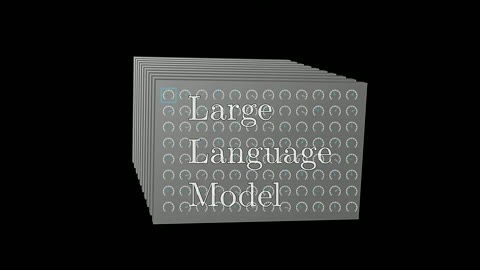
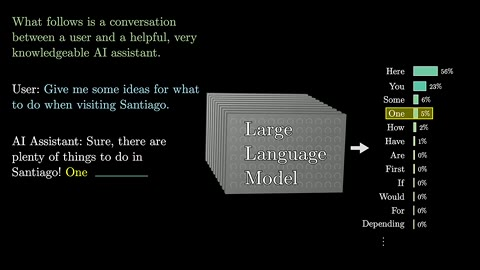
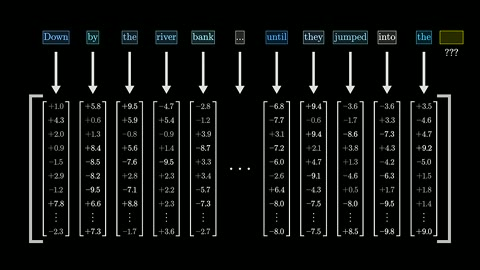
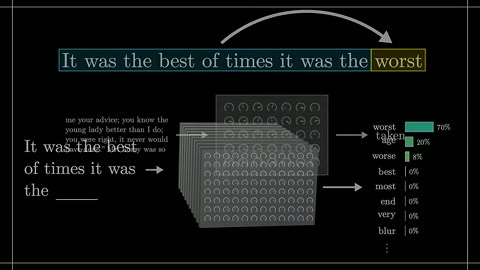
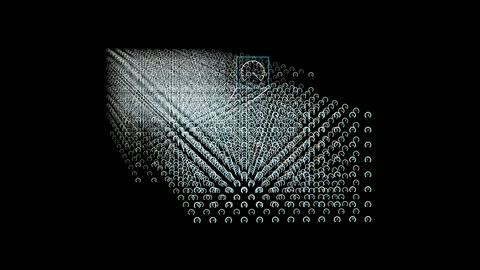
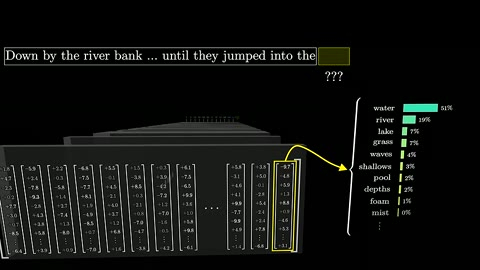

(6.0 s)


In [61]:
def merge_parts(results, found):
    out = []
    for pi in found:
        for c in results[pi]["citations"]:
            dup = next((o for o in out if o["video_id"] == c["video_id"] and abs(o["ms"] - c["ms"]) <= FUSION_WINDOW_S * 1000), None)
            if dup:
                dup["parts"] = sorted(set(dup["parts"] + [pi + 1]))
            else:
                out.append({**c, "parts": [pi + 1]})
    for i, c in enumerate(out, 1):
        c["n"] = i
    return out

def ask_engine(question, video_ids=None):
    with ThreadPoolExecutor(max_workers=2) as ex:
        f_ret = ex.submit(retrieve, question, video_ids)
        f_split = ex.submit(split_question, question)
        r, parts = f_ret.result(), f_split.result()
    opts = {}
    if len(parts) > 1:
        per_k = max(3, MULTI_QUERY_TOTAL_K // len(parts))
        with ThreadPoolExecutor(max_workers=len(parts)) as ex:
            results = list(ex.map(lambda p: retrieve(p, video_ids, top_k=per_k), parts))
        found = [i for i, x in enumerate(results) if x["citations"] and gate_ok(x["best_visual"], x["best_text"])]
        if not found:
            return {"question": question, "parts": parts, "answer": ABSTAIN, "citations": [], "llm_used": False}
        citations = merge_parts(results, found)
        opts = {"parts": parts, "missing": [i for i in range(len(parts)) if i not in found]}
    else:
        if not r["citations"]:
            return {"question": question, "citations": [], "llm_used": False,
                    "answer": ABSTAIN if r["candidates"] else "Nothing is indexed yet. Add a video first."}
        if not gate_ok(r["best_visual"], r["best_text"]):                        # check 1
            return {"question": question, "answer": ABSTAIN, "citations": [], "llm_used": False}
        citations = r["citations"]
    moments = build_moments(citations)
    answer = validate_citations(llm_answer(question, moments, **opts), len(moments))   # checks 2 + 3
    if not CITE.search(answer):
        citations = []                          # a "couldn't find it" reply shows no cards
    return {"question": question, "parts": parts, "answer": answer, "citations": citations, "llm_used": True}

def show_answer(res):
    if len(res.get("parts") or []) > 1:
        print("searched as:", " | ".join(res["parts"]))
    display(Markdown(res["answer"]))
    if not res.get("llm_used"):
        print("(no LLM call)")
    cards = []
    for c in res["citations"]:
        img = img_tag(get_bytes(frame_key(c["video_id"], c["preview_idx"])), 210) if c.get("preview_idx") is not None else ""
        when = f'<a href="{c["link"]}" target="_blank">{c["timestamp"]}</a>' if c.get("link") else c["timestamp"]
        said = f'<div style="font-size:11px;color:#666">{(c["speaker"] + ": ") if c.get("speaker") else ""}{short(c["transcript"], 140)}</div>' if c.get("transcript") else ""
        cards.append(f'<div style="width:220px;margin:4px;font:12px sans-serif">{img}<br><b>[{c["n"]}]</b> {when} · '
                     f'{c["match"]}% · {"+".join(c["modalities"])}<br><i>{short(c["title"], 40)}</i>{said}</div>')
    if cards:
        display(HTML(f'<div style="display:flex;flex-wrap:wrap">{"".join(cards)}</div>'))

t = time.time()
show_answer(ask_engine("What does a language model predict, and how is it trained?", video_ids=[VID]))
print(f"({time.time() - t:.1f} s)")

# Part 6. Your turn

Put YouTube links or file paths in `MY_VIDEOS` and run the next cells. Each video goes through the **Prefect flow** from Part 4 and lands in the **same collections** as the demo video, under the same user, so `ask()` searches all of them together.

* **Your own file:** upload it with the **Files** panel on the left (it goes to `/content/`), then add `"/content/my_video.mp4"` or just `"my_video.mp4"`.
* **Speaker names:** need `GEMINI_API_KEY`.
* **Time:** on CPU, turning frames into vectors takes a few minutes per video. A GPU runtime (Runtime → Change runtime type) takes seconds.
* **If YouTube blocks Colab:** fetch retries twice (30 s, then 2 min) before giving up. Add `SOCIALKIT_API_KEY`, or upload the file instead.

In [64]:
MY_VIDEOS = [
    # "https://www.youtube.com/watch?v=...",
    # "/content/my_video.mp4",
]

In [65]:
def index_video(source):
    """Add one video and run the whole Prefect flow on it."""
    vid = add_video(source, diarize=bool(GEMINI_API_KEY))
    state = ingest_video(vid, return_state=True)
    timeline(vid)
    if PREFECT_API_URL:
        from prefect.settings import PREFECT_UI_URL
        print("Prefect Cloud:", f"{PREFECT_UI_URL.value()}/runs/flow-run/{state.state_details.flow_run_id}")
    if not (state.is_completed() or VIDEOS[vid]["status"] == "skipped"):
        raise RuntimeError(VIDEOS[vid].get("error") or state.message)
    return vid

def library():
    """Every video in this notebook: status, frames, chunks, and any note."""
    table([[v, r["status"], short(r["title"] or r["url"] or r["path"], 50), r["frame_count"] or 0, r["chunks"],
            short(r["error"] or r["transcript_note"] or "", 90)] for v, r in VIDEOS.items()],
          ["video_id", "status", "title", "frames", "chunks", "note"])

def index_videos(sources):
    """Index each source in turn; one failure doesn't stop the rest."""
    for source in sources:
        print(f"\n=== {source}")
        try:
            vid = video_id(source)
            if vid in VIDEOS and VIDEOS[vid]["status"] == "indexed":
                print("already indexed")
                continue
            index_video(source)
        except Exception as exc:
            print(f"FAILED: {str(exc)[:300]}")
    print()
    library()

def ask(question, video_ids=None):
    """Ask across every indexed video, or only the ids in `video_ids` (see library())."""
    ids = video_ids or None
    print(f"Q: {question}   ({'videos: ' + ', '.join(ids) if ids else 'all your videos'})\n")
    show_answer(ask_engine(question, video_ids=ids))

In [66]:
index_videos(MY_VIDEOS)

video_id,status,title,frames,chunks,note
yt_LPZh9BOjkQs,indexed,Large Language Models explained briefly,155,21,


Q: What is the main point?   (videos: yt_LPZh9BOjkQs)



The main point is that large language models are sophisticated mathematical functions trained to predict the next word in a text, using vast amounts of data and computation, and their behavior emerges from the tuning of hundreds of billions of parameters through processes like pre-training and reinforcement learning with human feedback, resulting in fluent and useful text generation [1, 2, 3, 4, 6, 5].

Specifically, the model starts by predicting the next word in a given text, refining its parameters through backpropagation over many examples to improve accuracy [2]. This pre-training requires enormous computational resources, often measured in millions of years of operations, and is supplemented by reinforcement learning with human feedback to align the model's outputs with user preferences [3, 4]. The architecture known as the transformer allows efficient parallel processing of text, enabling this scale of training [4]. The model's predictions are emergent phenomena from the complex tuning of parameters, making it difficult to pinpoint exact reasons for specific outputs, but the results are impressively fluent and useful [6, 5].


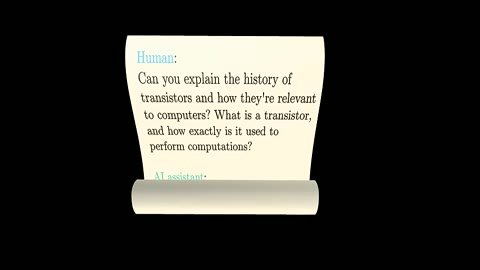
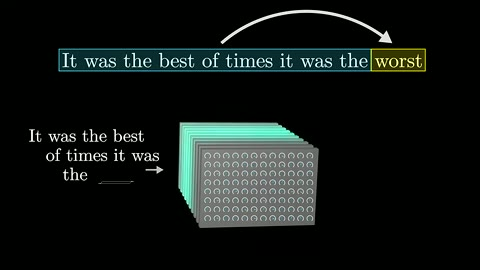
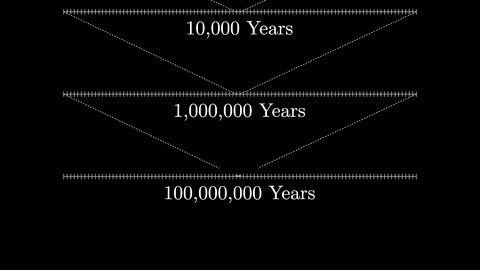
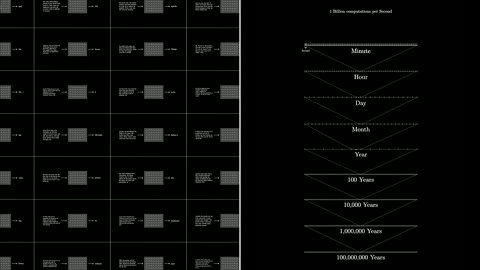
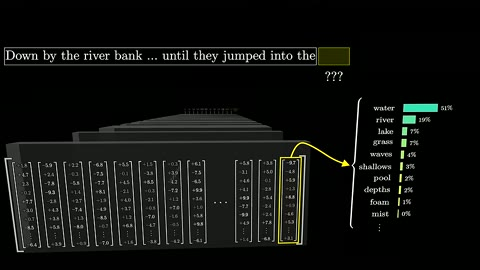
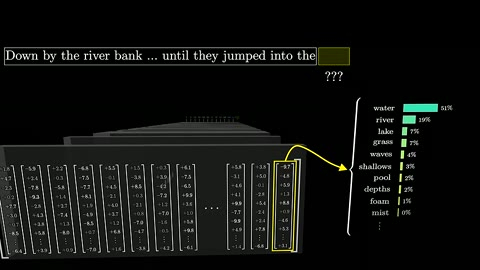

In [67]:
# Only some videos: pass their ids from the library table above.
ask("What is the main point?", video_ids=[VID]) #VID add video id
# ask("What is this video about?") #all videos